# Notebook 02 — Preprocessing and Sequence Construction

**Project:** Future water-quality class prediction using artificial intelligence
**Input:** Country-wise CSV files from `/kaggle/input/...`
**Active clients:** England, Ireland, and USA
**Output:** Model-ready sequence tensors, fitted feature transformers, audit tables, figures, and a preprocessing manifest.

## Purpose

This notebook prepares the water-quality data for the modeling experiments. The raw country-wise records are cleaned, organized monthly, and transformed into temporal sequences. Each sequence contains the previous 12 monthly observations of eight physicochemical parameters, and the target is the CCME water-quality class of the following month.

## Main Choices

The preprocessing follows the decisions made after the exploratory analysis:

* England, Ireland, and USA are used as active clients.
* Canada and China are not used in this stage because they do not provide suitable train/validation/test sequences for the selected forecasting setup.
* The task is defined as future class prediction, with a 12-month input window and a 1-month prediction horizon.
* `CCME_Values` is used only to derive the monthly target class, then removed from the input features to avoid target leakage.
* The split is chronological: training before 2018, validation from 2018 to 2019, and testing from 2020 onward.
* Feature scaling is fitted using training-period data only.
* Only complete valid sequences with a known future target are kept.
* A modal-value proxy mask is saved for later diagnostic analysis, but it is not used as a model input.

## Saved Outputs

The notebook saves the final tensors, fitted transformers, class-distribution tables, future-target checks, tensor-integrity checks, modal-value proxy summaries, figures, and `preprocess_manifest.json` in:

`/kaggle/working/preprocess_outputs/`

These outputs are used in the following notebooks for local, centralized, federated, explainability, and ablation experiments.


# Section 0 — Setup

Imports, project-wide constants, output directories, visual style, and saving helpers.
All values here are **locked** — they must not be changed after the notebook is run,
as downstream sections depend on them for reproducibility.

In [9]:
# ── Standard library ─────────────────────────────────────────────────────
import os
import json
import hashlib
import warnings
from datetime import datetime, timezone
from pathlib import Path

# ── Third-party ──────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# ── Configuration ────────────────────────────────────────────────────────
warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)

# ── Project constants (locked from EDA) ──────────────────────────────────
ACTIVE_CLIENTS  = ["England", "Ireland", "USA"]

# Sequence configuration
WINDOW          = 12          # months of historical context
HORIZON         = 1           # months ahead to predict

# Temporal split boundaries
VAL_START_YEAR  = 2018
TEST_START_YEAR = 2020

# Feature ordering — fixed for reproducibility
FEATURE_COLS    = ["NH3", "BOD", "DO", "PO4", "pH", "Temp", "Nitrogen", "Nitrate"]

# Per-feature transform: chemicals get log1p, physical features get identity
LOG_FEATURES    = ["NH3", "BOD", "PO4", "Nitrogen", "Nitrate"]
IDENTITY_FEATURES = ["pH", "Temp", "DO"]
assert set(LOG_FEATURES) | set(IDENTITY_FEATURES) == set(FEATURE_COLS), \
    "Feature partition must cover all FEATURE_COLS exactly once."

# Physical validity rules (from EDA Section 3.3)
VALIDITY_RULES  = {
    "NH3":      (0,    None),
    "BOD":      (0,    None),
    "DO":       (0,    None),
    "PO4":      (0,    None),
    "Nitrogen": (0,    None),
    "Nitrate":  (0,    None),
    "pH":       (0,    14),
    "Temp":     (-2,   45),
}

# CCME WQI classification thresholds (lower bound of each class)
# Standard CCME methodology; see EDA Section 4.2 for empirical determinism check
CCME_CLASS_THRESHOLDS = [
    (95, "Excellent"),
    (80, "Good"),
    (65, "Fair"),
    (45, "Marginal"),
    (0,  "Poor"),
]
CLASS_TO_INT = {"Excellent": 0, "Good": 1, "Fair": 2, "Marginal": 3, "Poor": 4}
INT_TO_CLASS = {v: k for k, v in CLASS_TO_INT.items()}
# Note: this is a categorical encoding (CrossEntropy treats integers as nominal),
# not an ordinal one. Any permutation would be equivalent.

print(f"Configuration locked.")
print(f"  Active clients:    {ACTIVE_CLIENTS}")
print(f"  Window × horizon:  {WINDOW} × {HORIZON} months")
print(f"  Split boundaries:  train < {VAL_START_YEAR}, val {VAL_START_YEAR}–{TEST_START_YEAR-1}, test ≥ {TEST_START_YEAR}")
print(f"  Feature transform: log1p on {LOG_FEATURES}, identity on {IDENTITY_FEATURES}")

Configuration locked.
  Active clients:    ['England', 'Ireland', 'USA']
  Window × horizon:  12 × 1 months
  Split boundaries:  train < 2018, val 2018–2019, test ≥ 2020
  Feature transform: log1p on ['NH3', 'BOD', 'PO4', 'Nitrogen', 'Nitrate'], identity on ['pH', 'Temp', 'DO']


In [10]:
# We locate the Kaggle input folder by checking where the three country CSV files are actually mounted.
# This does not change the dataset or the methodology; it only avoids relying on one fragile Kaggle path.

from pathlib import Path

KAGGLE_INPUT_ROOT = Path("/kaggle/input")


def find_country_wise_data_dir(active_clients):
    """Find the folder that contains England/Ireland/USA country CSV files."""
    required_files = [f"{client}_dataset.csv" for client in active_clients]

    # Known locations are tried first for speed and transparency.
    candidate_dirs = [
        KAGGLE_INPUT_ROOT / "datasets" / "sarahaddouda" / "water-quality-index" / "Dataset" / "Country-Wise Data",
        KAGGLE_INPUT_ROOT / "water-quality-index" / "Dataset" / "Country-Wise Data",
        KAGGLE_INPUT_ROOT / "water-quality-index" / "Country-Wise Data",
        KAGGLE_INPUT_ROOT / "water-quality" / "Dataset" / "Country-Wise Data",
        KAGGLE_INPUT_ROOT / "water-quality" / "Country-Wise Data",
    ]

    # If Kaggle mounted the dataset under another slug, search for the England file and test its folder.
    if KAGGLE_INPUT_ROOT.exists():
        for england_file in KAGGLE_INPUT_ROOT.rglob("England_dataset.csv"):
            candidate_dirs.append(england_file.parent)

    valid_dirs = []
    for d in candidate_dirs:
        if all((d / fname).exists() for fname in required_files):
            valid_dirs.append(d)

    # Remove duplicates while keeping a stable order.
    unique_valid_dirs = []
    seen = set()
    for d in valid_dirs:
        key = str(d)
        if key not in seen:
            seen.add(key)
            unique_valid_dirs.append(d)

    if len(unique_valid_dirs) == 0:
        print("The notebook could not find the country-wise CSV files under /kaggle/input.")
        print("This usually means the dataset was not attached to this Kaggle notebook, or it was mounted under an unexpected folder.")
        print("\nFiles currently visible under /kaggle/input:")
        if KAGGLE_INPUT_ROOT.exists():
            for p in sorted(KAGGLE_INPUT_ROOT.glob("*")):
                print(" -", p)
        else:
            print(" - /kaggle/input does not exist in this environment")
        raise FileNotFoundError(
            "Could not locate a Country-Wise Data folder containing England_dataset.csv, "
            "Ireland_dataset.csv, and USA_dataset.csv. Attach the same Kaggle dataset, then rerun this cell."
        )

    if len(unique_valid_dirs) > 1:
        print("More than one possible country-wise dataset folder was found:")
        for d in unique_valid_dirs:
            print(" -", d)
        raise RuntimeError(
            "More than one matching dataset folder was found. To avoid using the wrong copy, "
            "set COUNTRY_DIR manually to the intended folder."
        )

    return unique_valid_dirs[0]


COUNTRY_DIR = find_country_wise_data_dir(ACTIVE_CLIENTS)
DATA_ROOT = COUNTRY_DIR.parent

OUTPUT_DIR = "/kaggle/working/preprocess_outputs"
TENSOR_DIR = os.path.join(OUTPUT_DIR, "tensors")
SCALER_DIR = os.path.join(OUTPUT_DIR, "scalers")
AUDIT_DIR = os.path.join(OUTPUT_DIR, "audit")

for d in (OUTPUT_DIR, TENSOR_DIR, SCALER_DIR, AUDIT_DIR):
    os.makedirs(d, exist_ok=True)

# Manifest scaffold — populated section by section, written in Section 9
manifest = {
    "notebook":              "02_preprocess.ipynb",
    "stage":                 "Stage 1 (imputation preserved)",
    "created_utc":           datetime.now(timezone.utc).isoformat(),
    "seed":                  SEED,
    "active_clients":        ACTIVE_CLIENTS,
    "window":                WINDOW,
    "horizon":               HORIZON,
    "val_start_year":        VAL_START_YEAR,
    "test_start_year":       TEST_START_YEAR,
    "feature_cols":          FEATURE_COLS,
    "log_features":          LOG_FEATURES,
    "identity_features":     IDENTITY_FEATURES,
    "validity_rules":        {k: list(v) for k, v in VALIDITY_RULES.items()},
    "ccme_thresholds":       CCME_CLASS_THRESHOLDS,
    "class_to_int":          CLASS_TO_INT,
    "input_folder":          str(COUNTRY_DIR),
    "input_files":           {},      # SHA-256 hashes added in Section 1
    "modal_constants":       {},      # added in Section 7 (per (client, feature))
    "scaler_statistics":     {},      # added in Section 6 (per client per feature)
    "sequence_counts":       {},      # added in Section 7 (per client per split)
    "class_distribution":    {},      # added in Section 8 (per client per split)
}

print(f"Country-wise data folder: {COUNTRY_DIR}")
print(f"Output directory: {OUTPUT_DIR}")
print(f"  ├── tensors/       (per-client .npz files)")
print(f"  ├── scalers/       (per-client .joblib files)")
print(f"  └── audit/         (CSVs for sanity checks)")


Country-wise data folder: /kaggle/input/datasets/sarahaddouda/water-quality-index/Dataset/Country-Wise Data
Output directory: /kaggle/working/preprocess_outputs
  ├── tensors/       (per-client .npz files)
  ├── scalers/       (per-client .joblib files)
  └── audit/         (CSVs for sanity checks)


In [11]:
# This cell keeps the preprocessing notebook aligned with the final thesis task.
# The model must learn from past water-quality measurements, not from the CCME score itself.

EXPECTED_FEATURES = ["NH3", "BOD", "DO", "PO4", "pH", "Temp", "Nitrogen", "Nitrate"]

assert FEATURE_COLS == EXPECTED_FEATURES, (
    "The input feature list has changed. For Stage 1, the notebook must use "
    "the same eight physicochemical parameters defined in the methodology."
)

for forbidden_col in ["CCME_Values", "CCME_WQI", "target_class", "target_int"]:
    assert forbidden_col not in FEATURE_COLS, (
        f"{forbidden_col} must not be used as an input feature."
    )

assert WINDOW == 12, "The thesis setup uses the previous 12 monthly observations."
assert HORIZON == 1, "The thesis setup predicts one month ahead."
assert VAL_START_YEAR == 2018, "The validation period should start in 2018."
assert TEST_START_YEAR == 2020, "The test period should start in 2020."

manifest["problem_formulation"] = {
    "task_type": "sequence-to-class forecasting",
    "input_window": "previous 12 monthly observations",
    "forecast_horizon": "next month",
    "target": "future CCME water-quality class",
    "input_features": FEATURE_COLS,
    "excluded_from_inputs": ["CCME_Values", "CCME_WQI"],
    "active_clients": ACTIVE_CLIENTS,
    "split_rule": "train < 2018, validation 2018-2019, test >= 2020",
    "reason": (
        "The task is formulated as future class prediction to avoid the weak "
        "same-time shortcut of mapping CCME_Values directly to CCME_WQI."
    ),
}

print("Task definition checked.")
print("The notebook is set to predict the next-month CCME class from the previous 12 months.")
print("CCME_Values and CCME_WQI are not part of the input feature list.")


Task definition checked.
The notebook is set to predict the next-month CCME class from the previous 12 months.
CCME_Values and CCME_WQI are not part of the input feature list.


In [12]:
# ── Active clients only (Canada and China excluded — EDA Section 6) ──────
COUNTRY_COLORS = {
    "England": "#55A868",   # green
    "Ireland": "#C44E52",   # red
    "USA":     "#8172B2",   # purple
}

# ── Plot defaults (consistent with Notebook 01) ───────────────────────────
plt.rcParams.update({
    "figure.figsize":    (10, 5),
    "figure.dpi":        110,
    "savefig.dpi":       250,
    "savefig.bbox":      "tight",
    "font.size":         11,
    "axes.titlesize":    12,
    "axes.labelsize":    11,
    "axes.grid":         True,
    "grid.alpha":        0.25,
    "axes.spines.top":   False,
    "axes.spines.right": False,
})
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# ── Saving helpers ────────────────────────────────────────────────────────
FIG_DIR   = os.path.join(OUTPUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

def save_figure(name, fig=None, formats=("png", "pdf")):
    """Save a figure to FIG_DIR in PNG (for viewing) and PDF (for thesis)."""
    fig = fig or plt.gcf()
    for ext in formats:
        path = os.path.join(FIG_DIR, f"{name}.{ext}")
        fig.savefig(path)
    print(f"✓ saved figure: {name}.{'/'.join(formats)}")

def save_table(df, name):
    """Save a DataFrame to AUDIT_DIR as CSV."""
    path = os.path.join(AUDIT_DIR, f"{name}.csv")
    df.to_csv(path, index=False)
    print(f"✓ saved table : {name}.csv  ({df.shape[0]}×{df.shape[1]})")

# Section 1 — Load and verify input CSVs

We load only the three active clients (England, Ireland, USA). Canada and China are not loaded in the main Stage 1 preprocessing pipeline because the EDA sequence-feasibility analysis supported their exclusion from the active federation.

For reproducibility, we compute the SHA-256 hash of each input CSV. The hash is recorded in the manifest. If a reviewer later wants to verify that the analysis was run on the exact published data, they recompute the hashes and compare.

In [13]:
def sha256_of_file(path, chunk_size=8192):
    """Compute SHA-256 hex digest of a file by streaming bytes."""
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while chunk := f.read(chunk_size):
            h.update(chunk)
    return h.hexdigest()


rename_map = {
    "Ammonia (mg/l)":                   "NH3",
    "Biochemical Oxygen Demand (mg/l)": "BOD",
    "Dissolved Oxygen (mg/l)":          "DO",
    "Orthophosphate (mg/l)":            "PO4",
    "pH (ph units)":                    "pH",
    "Temperature (cel)":                "Temp",
    "Nitrogen (mg/l)":                  "Nitrogen",
    "Nitrate (mg/l)":                   "Nitrate",
    "Waterbody Type":                   "Waterbody_Type",
}

# These prefixes come from the successful preprocessing run. They protect us from silently using a different file.
EXPECTED_SHA256_PREFIX = {
    "England": "aa32adf3fcb48d56",
    "Ireland": "516d1190c24838ac",
    "USA":     "21e7a6f8db36edd3",
}

raw = {}
print(f"{'Client':10s} {'Rows':>10s} {'SHA-256 (first 16)':<18s}  Status")
print("-" * 65)
for client in ACTIVE_CLIENTS:
    path = os.path.join(str(COUNTRY_DIR), f"{client}_dataset.csv")
    assert os.path.exists(path), f"Input file not found: {path}"

    digest = sha256_of_file(path)
    assert digest.startswith(EXPECTED_SHA256_PREFIX[client]), (
        f"The {client} file was found, but its hash does not match the file used in the validated run.\n"
        f"Expected prefix: {EXPECTED_SHA256_PREFIX[client]}\n"
        f"Found prefix:    {digest[:16]}\n"
        "Stop here and check that the same Kaggle dataset is attached."
    )

    manifest["input_files"][client] = {
        "path":   path,
        "sha256": digest,
    }

    df = pd.read_csv(path)
    df = df.rename(columns=rename_map)
    df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y", errors="coerce")

    # The site identifier follows the same monitoring-context definition used in the methodology.
    df["site_id"] = df["Area"].astype(str) + "__" + df["Waterbody_Type"].astype(str)

    raw[client] = df
    print(f"{client:10s} {len(df):>10,} {digest[:16]}  loaded and verified")

# Schema sanity check
expected_cols = set(FEATURE_COLS) | {"Date", "Area", "Waterbody_Type", "CCME_Values", "CCME_WQI", "site_id"}
for client, df in raw.items():
    missing = expected_cols - set(df.columns)
    assert not missing, f"{client} missing columns: {missing}"
print("\nAll clients pass schema and file-identity checks.")


Client           Rows SHA-256 (first 16)  Status
-----------------------------------------------------------------
England     2,129,198 aa32adf3fcb48d56  loaded and verified
Ireland       235,019 516d1190c24838ac  loaded and verified
USA           413,814 21e7a6f8db36edd3  loaded and verified

All clients pass schema and file-identity checks.


# Section 2 — Pure helper functions

Each preprocessing step is implemented as a pure, stateless function. This makes every step independently testable, traceable to its rule, and free of hidden state. The functions are applied in order in Section 3.

The implementation rules:
- Each function takes a DataFrame and returns a DataFrame.
- At this stage, the functions are only defined; they are executed and validated in the following section.
- No function mutates its input (always `df.copy()` or `.reset_index()`).
- No function depends on global variables other than the locked constants from Section 0.

In [14]:
def drop_exact_duplicates(df):
    """Remove rows identical across all columns."""
    return df.drop_duplicates().reset_index(drop=True)


def drop_invalid_rows(df, rules=VALIDITY_RULES):
    """Drop rows where any feature falls outside its physically valid range."""
    df = df.copy()
    invalid_mask = pd.Series(False, index=df.index)
    for col, (lo, hi) in rules.items():
        if lo is not None:
            invalid_mask |= (df[col] < lo)
        if hi is not None:
            invalid_mask |= (df[col] > hi)
    return df.loc[~invalid_mask].reset_index(drop=True)


def aggregate_site_date(df, feature_cols=FEATURE_COLS, target_col="CCME_Values"):
    """Collapse rows sharing (site_id, Date) by per-feature median.
    Handles intra-day measurements, repeated sampling, and station merging
    consistently (EDA Section 3.2)."""
    agg_cols = feature_cols + [target_col]
    return (
        df.groupby(["site_id", "Date"], as_index=False)[agg_cols]
          .median()
    )


def monthly_resample(df, feature_cols=FEATURE_COLS, target_col="CCME_Values"):
    """Per site, take the median over each calendar month. Months with no
    measurements remain as NaN, which propagates to sequence rejection later.
    Returns columns: [site_id, year_month, <features>, CCME_Values]."""
    agg_cols = feature_cols + [target_col]
    df = df.copy()
    df = df.set_index("Date")
    monthly = (
        df.groupby("site_id")[agg_cols]
          .resample("ME")
          .median()
          .reset_index()
    )
    monthly = monthly.rename(columns={"Date": "year_month"})
    return monthly


def ccme_value_to_class(v, thresholds=CCME_CLASS_THRESHOLDS):
    """Map a continuous CCME score to its discrete class label.
    Standard CCME methodology (≥95 Excellent, ≥80 Good, etc.).
    Returns None for NaN input."""
    if pd.isna(v):
        return None
    for threshold, cls in thresholds:
        if v >= threshold:
            return cls
    return None  # unreachable given thresholds include 0

# Section 3 — Per-client deterministic preprocessing

We apply the four preprocessing steps from Section 2 to each active client
in a fixed order. No parameters are fitted here — every operation is
deterministic and operates on raw values only.

**Step order and justification:**
1. Drop exact duplicates — removes compilation noise before any aggregation.
2. Drop physically invalid rows — removes sensor errors before they can
   contaminate the medians computed in step 3.
3. Aggregate same-(site_id, Date) rows by per-feature median — resolves
   intra-day measurements, repeated sampling, and the multi-station
   collapsing artifact introduced by the site_id construction (EDA §3.2).
4. Monthly-resample per site — one row per (site_id, calendar month),
   median across all daily measurements within the month. Months with no
   measurements are retained as NaN rows; they will be rejected during
   sequence building (Section 7).

**Note on row count after step 4.** The monthly-resampled dataframe will
contain *more* rows than the raw data. This is correct: resampling generates
a row for every calendar month in each site's observation span. For a site
monitored from 2000 to 2023, that is 276 monthly rows regardless of how
many raw measurements exist. The NaN months are visible but unused.

In [15]:
# ── Section 3 — Per-client deterministic preprocessing ───────────────────

processed  = {}    # monthly-resampled DataFrames, one per client
audit_rows = []    # data-reduction audit per client

for client in ACTIVE_CLIENTS:
    df = raw[client].copy()
    n0 = len(df)

    # Step 1 — exact duplicates
    df = drop_exact_duplicates(df)
    n1 = len(df)

    # Step 2 — invalid rows
    df = drop_invalid_rows(df)
    n2 = len(df)

    # Step 3 — aggregate same-(site_id, Date) by median
    df = aggregate_site_date(df)
    n3 = len(df)

    # Step 4 — monthly resample per site
    df = monthly_resample(df)
    n4 = len(df)

    n_sites = df["site_id"].nunique()
    processed[client] = df

    audit_rows.append({
        "Client":          client,
        "Raw":             n0,
        "Dropped_dups":    n0 - n1,
        "Dropped_invalid": n1 - n2,
        "Aggregated":      n2 - n3,
        "Monthly_rows":    n4,
        "N_sites":         n_sites,
    })

audit_df = pd.DataFrame(audit_rows)
save_table(audit_df, "03_preprocessing_audit")

print("✓ Preprocessing pipeline applied to all three active clients.")
print("  Monthly-resampled DataFrames are stored in `processed`.\n")
print("Per-client data reduction per step:")
audit_df 

✓ saved table : 03_preprocessing_audit.csv  (3×7)
✓ Preprocessing pipeline applied to all three active clients.
  Monthly-resampled DataFrames are stored in `processed`.

Per-client data reduction per step:


,Client,Raw,Dropped_dups,Dropped_invalid,Aggregated,Monthly_rows,N_sites
0,England,2129198,1301,80,74288,5275901,56314
1,Ireland,235019,26,559,7927,584745,9733
2,USA,413814,8569,6617,270281,108751,661


# Section 4 — Label derivation and feature/label separation

We convert monthly `CCME_Values` to a discrete class label using the standard
CCME WQI thresholds, then drop `CCME_Values` from each client's DataFrame so
it can never appear in the model's input features.

**Why the label is recomputed at the monthly level.** Each raw row already
carries a `CCME_WQI` label, but those labels apply to single-timestep
measurements. After monthly resampling, each row contains the median across
all daily measurements within that month — the original labels no longer
correspond to the new aggregated values. Recomputing the label from the
monthly median keeps the target consistent with the features the model will
see.

**Thresholds.** Standard CCME methodology:
- `CCME_Values ≥ 95`  → Excellent (encoded as 0)
- `CCME_Values ≥ 80`  → Good (1)
- `CCME_Values ≥ 65`  → Fair (2)
- `CCME_Values ≥ 45`  → Marginal (3)
- `CCME_Values <  45`  → Poor (4)

**`CCME_Values` is dropped immediately after label derivation.** It is the
deterministic source of the label (EDA §4.2) and must not appear in the
feature matrix. Dropping it explicitly in this section makes the
leakage-prevention step traceable for a reviewer.

## 4.A — Derive monthly class labels and audit distribution

In [16]:
monthly_class_dist = []        # audit: monthly class distribution per client

for client in ACTIVE_CLIENTS:
    df = processed[client]

    # 1. Derive class label from monthly median CCME_Values
    df["target_class"] = df["CCME_Values"].apply(ccme_value_to_class)

    # 2. Encode class string → integer (0..4); leave NaN labels as NaN
    df["target_int"] = df["target_class"].map(CLASS_TO_INT)

    # 3. Audit: count class distribution among non-null labels
    n_total      = len(df)
    n_with_label = int(df["target_class"].notna().sum())
    counts = df["target_class"].value_counts(normalize=True).reindex(
        ["Excellent", "Good", "Fair", "Marginal", "Poor"], fill_value=0
    ) * 100

    monthly_class_dist.append({
        "Client":           client,
        "Monthly_rows":     n_total,
        "Rows_with_label":  n_with_label,
        "Excellent_%":      round(counts["Excellent"], 2),
        "Good_%":           round(counts["Good"], 2),
        "Fair_%":           round(counts["Fair"], 2),
        "Marginal_%":       round(counts["Marginal"], 2),
        "Poor_%":           round(counts["Poor"], 2),
    })

class_dist_df = pd.DataFrame(monthly_class_dist)
save_table(class_dist_df, "04_monthly_class_distribution")

print("Monthly class distribution per client (after monthly resampling):")
class_dist_df   # ← renders as HTML table

✓ saved table : 04_monthly_class_distribution.csv  (3×8)
Monthly class distribution per client (after monthly resampling):


,Client,Monthly_rows,Rows_with_label,Excellent_%,Good_%,Fair_%,Marginal_%,Poor_%
0,England,5275901,1743985,21.04,43.52,15.10,14.62,5.72
1,Ireland,584745,198627,84.84,13.57,0.87,0.28,0.43
2,USA,108751,56028,91.08,8.37,0.44,0.11,0.00


## 4.B — Drop CCME_Values from features, verify no leakage 

In [17]:
for client in ACTIVE_CLIENTS:
    processed[client] = processed[client].drop(columns=["CCME_Values"])

print("Leakage check — CCME_Values must NOT appear in any client's columns:\n")
for client in ACTIVE_CLIENTS:
    cols = list(processed[client].columns)
    assert "CCME_Values" not in cols, f"LEAKAGE: CCME_Values still in {client}"
    print(f"  {client:10s} → {cols}")

print("\n✓ CCME_Values removed from all client DataFrames — one leakage path closed.")

Leakage check — CCME_Values must NOT appear in any client's columns:

  England    → ['site_id', 'year_month', 'NH3', 'BOD', 'DO', 'PO4', 'pH', 'Temp', 'Nitrogen', 'Nitrate', 'target_class', 'target_int']
  Ireland    → ['site_id', 'year_month', 'NH3', 'BOD', 'DO', 'PO4', 'pH', 'Temp', 'Nitrogen', 'Nitrate', 'target_class', 'target_int']
  USA        → ['site_id', 'year_month', 'NH3', 'BOD', 'DO', 'PO4', 'pH', 'Temp', 'Nitrogen', 'Nitrate', 'target_class', 'target_int']

✓ CCME_Values removed from all client DataFrames — one leakage path closed.


# Section 5 — Monthly temporal split audit per client
This section is a **monthly split audit**. It counts how many monthly rows and labeled rows fall into each calendar period:

- train: before 2018
- validation: 2018–2019
- test: 2020 onward

The `splits` dictionary is kept as an audit/reference object only. It does not define the final sequence samples, and Section 6 fits preprocessing statistics directly from `processed[client]` using the training-period condition (`year_month < 2018`).

In Section 7, valid 12-month sequences are built from the full monthly timeline, then assigned to train, validation, or test using the sequence `target_date`. This allows valid forecasting windows such as 2017 inputs → 2018 target, without leakage, because all input months still occur before the target month.

Leakage is controlled by fitting preprocessing statistics on training-period rows only and by constructing `X` only from `FEATURE_COLS`, excluding target-derived columns.

## 5.A — Monthly split audit

This cell counts how many monthly rows and labeled monthly rows fall into the
training, validation, and test calendar periods. It is an audit of temporal
coverage only. The final forecasting samples are still created later from valid
12-month windows and assigned to a split using their target date.


In [18]:
# ── Section 5 — Temporal split per client ────────────────────────────────

splits     = {client: {} for client in ACTIVE_CLIENTS}
split_audit = []

for client in ACTIVE_CLIENTS:
    df = processed[client].copy()
    year = df["year_month"].dt.year

    train_mask = (year <  VAL_START_YEAR)
    val_mask   = (year >= VAL_START_YEAR) & (year < TEST_START_YEAR)
    test_mask  = (year >= TEST_START_YEAR)

    df_train = df.loc[train_mask].reset_index(drop=True)
    df_val   = df.loc[val_mask].reset_index(drop=True)
    df_test  = df.loc[test_mask].reset_index(drop=True)

    splits[client]["train"] = df_train
    splits[client]["val"]   = df_val
    splits[client]["test"]  = df_test

    split_audit.append({
        "Client":        client,
        "Train_rows":    len(df_train),
        "Val_rows":      len(df_val),
        "Test_rows":     len(df_test),
        "Train_labeled": int(df_train["target_int"].notna().sum()),
        "Val_labeled":   int(df_val["target_int"].notna().sum()),
        "Test_labeled":  int(df_test["target_int"].notna().sum()),
        "Train_dates":   f"{df_train['year_month'].min().strftime('%Y-%m')} → "
                         f"{df_train['year_month'].max().strftime('%Y-%m')}",
        "Test_dates":    f"{df_test['year_month'].min().strftime('%Y-%m')} → "
                         f"{df_test['year_month'].max().strftime('%Y-%m')}",
    })

split_audit_df = pd.DataFrame(split_audit)
save_table(split_audit_df, "05_temporal_split_audit")

# ── Sanity check: train period must end strictly before val starts ───────
for client in ACTIVE_CLIENTS:
    if len(splits[client]["train"]) and len(splits[client]["val"]):
        train_max = splits[client]["train"]["year_month"].max()
        val_min   = splits[client]["val"]["year_month"].min()
        assert train_max < val_min, f"{client}: train overlaps with val"
    if len(splits[client]["val"]) and len(splits[client]["test"]):
        val_max  = splits[client]["val"]["year_month"].max()
        test_min = splits[client]["test"]["year_month"].min()
        assert val_max < test_min, f"{client}: val overlaps with test"

print("✓ Monthly temporal split audit created per client. No date overlap between splits.")
print("  Monthly DataFrames stored in `splits[client][\"train\"/\"val\"/\"test\"]`.\n")
print("Per-client split audit:")
split_audit_df

✓ saved table : 05_temporal_split_audit.csv  (3×9)
✓ Monthly temporal split audit created per client. No date overlap between splits.
  Monthly DataFrames stored in `splits[client]["train"/"val"/"test"]`.

Per-client split audit:


,Client,Train_rows,Val_rows,Test_rows,Train_labeled,Val_labeled,Test_labeled,Train_dates,Test_dates
0,England,4471908,349481,454512,1499299,97668,147018,2000-01 → 2017-12,2020-01 → 2023-10
1,Ireland,389197,81397,114151,131394,24861,42372,1940-11 → 2017-12,2020-01 → 2023-12
2,USA,102052,2559,4140,50769,1946,3313,1940-01 → 2017-12,2020-01 → 2023-07


## 5.B — Sequence-count validation checkpoint
This checkpoint verifies that the clean preprocessing pipeline reproduces the sequence counts obtained during the EDA. We port the EDA's `count_valid_sequences`
helper (Section 6 of `01_eda.ipynb`), apply it to each client's full monthly
DataFrame, assign each emitted sequence to a split by `target_date.year`,
and compare the resulting counts against those reported in EDA Section 6.

A zero difference (`Δ = 0`) confirms that the deterministic pipeline
in this notebook reproduces the EDA's feasibility analysis exactly. Only
then is it safe to proceed to Section 6 (scaler fit).

**Expected counts (EDA Section 6.2 / `06_sequence_counts_by_split.csv`):**

| Client  | Train  | Val   | Test   |
|---------|-------:|------:|-------:|
| England | 76,530 | 8,490 | 11,942 |
| Ireland | 27,778 | 4,296 |  5,887 |
| USA     | 30,222 | 1,770 |  1,979 |


In [19]:
# ── 5.B.1 — Port of EDA count_valid_sequences + apply per client ──────────
import time

def count_valid_sequences(monthly_df, window=WINDOW, horizon=HORIZON,
                          feature_cols=FEATURE_COLS,
                          target_col="target_int",
                          date_col="year_month"):
    """Direct port of EDA Section 6's count_valid_sequences.

    A sequence is emitted iff:
      * the site has at least window + horizon monthly rows,
      * every feature cell in the window is non-NaN,
      * the target label at index (window + horizon - 1) is non-NaN.

    Returns
    -------
    DataFrame with one row per valid sequence:
        columns = [site_id, target_date, target_year]
    """
    L, h = window, horizon
    records = []

    for site_id, sdf in monthly_df.groupby("site_id"):
        sdf = sdf.sort_values(date_col).reset_index(drop=True)
        n   = len(sdf)
        if n < L + h:
            continue

        valid_features = (~sdf[feature_cols].isna().any(axis=1)).values
        valid_target   = (~sdf[target_col].isna()).values
        dates          = sdf[date_col].values

        for i in range(n - L - h + 1):
            t = i + L + h - 1
            if valid_features[i:i+L].all() and valid_target[t]:
                records.append({
                    "site_id":     site_id,
                    "target_date": dates[t],
                    "target_year": pd.Timestamp(dates[t]).year,
                })

    return pd.DataFrame(records)


# Apply to each client. We pass `processed[client]` — the full monthly
# DataFrame from Section 3 — NOT the splits dict from Section 5. The
# function operates on the entire timeline; split assignment happens below.
sequence_catalog = {}
print("Counting valid sequences per client "
      "(1-3 minutes per client; England is the slowest):\n")

for client in ACTIVE_CLIENTS:
    t0 = time.time()
    seqs = count_valid_sequences(processed[client])
    sequence_catalog[client] = seqs
    print(f"  [{client:<8}] {len(seqs):>10,} valid sequences   "
          f"({time.time()-t0:.1f}s)")


Counting valid sequences per client (1-3 minutes per client; England is the slowest):

  [England ]     96,962 valid sequences   (76.2s)
  [Ireland ]     37,961 valid sequences   (10.4s)
  [USA     ]     33,971 valid sequences   (1.2s)


In [20]:
# ── 5.B.2 — Split assignment by target_year + comparison to EDA ───────────

EDA_EXPECTED = {
    "England": {"train": 76_530, "val":  8_490, "test": 11_942},
    "Ireland": {"train": 27_778, "val":  4_296, "test":  5_887},
    "USA":     {"train": 30_222, "val":  1_770, "test":  1_979},
}

rows = []
for client in ACTIVE_CLIENTS:
    seqs = sequence_catalog[client]
    if len(seqs) == 0:
        n_train = n_val = n_test = 0
    else:
        n_train = int((seqs["target_year"] <  VAL_START_YEAR).sum())
        n_val   = int(((seqs["target_year"] >= VAL_START_YEAR) &
                       (seqs["target_year"] <  TEST_START_YEAR)).sum())
        n_test  = int((seqs["target_year"] >= TEST_START_YEAR).sum())

    e = EDA_EXPECTED[client]
    rows.append({
        "Client":         client,
        "Train":          n_train,
        "Train_expected": e["train"],
        "Train_Δ":        n_train - e["train"],
        "Val":            n_val,
        "Val_expected":   e["val"],
        "Val_Δ":          n_val   - e["val"],
        "Test":           n_test,
        "Test_expected":  e["test"],
        "Test_Δ":         n_test  - e["test"],
    })

validation_df = pd.DataFrame(rows)
save_table(validation_df, "05B_sequence_count_validation")

# Record in the running manifest
manifest["sequence_counts"] = {
    r["Client"]: {"train": r["Train"], "val": r["Val"], "test": r["Test"]}
    for r in rows
}

print(f"Split: train < {VAL_START_YEAR} | "
      f"val {VAL_START_YEAR}-{TEST_START_YEAR-1} | "
      f"test ≥ {TEST_START_YEAR}   "
      f"(window={WINDOW}, horizon={HORIZON})\n")
print(validation_df.to_string(index=False))

total_abs_delta = validation_df[["Train_Δ", "Val_Δ", "Test_Δ"]].abs().sum().sum()
print(f"\nTotal |Δ| across all (client × split) cells: {total_abs_delta}")

if total_abs_delta == 0:
    print("\n✅  SEQUENCE-COUNT CHECKPOINT PASSED — counts reproduce EDA exactly.")
    print("    Safe to proceed to Section 6 (feature transformation and scaling).")
else:
    print("\n❌  SEQUENCE-COUNT CHECKPOINT FAILED — pipeline diverges from EDA.")    
    print("    Most likely causes, in decreasing order of probability:")
    print("    1. site_id constructed from different columns than EDA Section 3")
    print("       (must be: Area + \"__\" + Waterbody_Type)")
    print("    2. Date parsed with different format than \"%d-%m-%Y\"")
    print("    3. VALIDITY_RULES bounds differ from EDA Section 3.3")
    print("    4. monthly_resample using different frequency than \"ME\"")
    print("    5. aggregate_site_date grouping by different keys")
    print("    Stop here and debug before any further work.")


✓ saved table : 05B_sequence_count_validation.csv  (3×10)
Split: train < 2018 | val 2018-2019 | test ≥ 2020   (window=12, horizon=1)

 Client  Train  Train_expected  Train_Δ  Val  Val_expected  Val_Δ  Test  Test_expected  Test_Δ
England  76530           76530        0 8490          8490      0 11942          11942       0
Ireland  27778           27778        0 4296          4296      0  5887           5887       0
    USA  30222           30222        0 1770          1770      0  1979           1979       0

Total |Δ| across all (client × split) cells: 0

✅  SEQUENCE-COUNT CHECKPOINT PASSED — counts reproduce EDA exactly.
    Safe to proceed to Section 6 (feature transformation and scaling).


# Section 6 — Feature transformation and scaling

This section prepares the eight input features for sequence modelling. It does
not create tensors yet; it only transforms the monthly feature columns in
`processed[client]`.

The transformation is:

1. apply `log1p` to the strongly right-skewed chemistry concentration features:
   `NH3`, `BOD`, `PO4`, `Nitrogen`, and `Nitrate`;
2. keep `DO`, `pH`, and `Temp` on their original scale before standardization;
3. fit a `StandardScaler` separately for each client using complete feature rows
   from the training period only (`year_month < 2018`);
4. apply the fitted transformer to the full monthly timeline.

Before overwriting the feature columns, we save `processed_raw[client]`, which
contains the raw-scale monthly feature values. This snapshot will be used in
Section 7 to build the modal-value proxy mask. The transformed values in
`processed[client]` will be used for `X`.

Skeleton monthly rows containing `NaN` values are not removed here. They are
excluded only when fitting the scaler and are rejected later during sequence
construction.

## 6.A — Define the feature transformer

This cell defines the feature groups and the transformer class used for scaling.
It does not modify the data yet. The actual transformation is applied in
Section 6.B.


In [21]:
# ── 6.A — Feature-transform constants and class definition ───────────────

LOG1P_FEATURES  = ["NH3", "BOD", "PO4", "Nitrogen", "Nitrate"]
LINEAR_FEATURES = ["DO", "pH", "Temp"]

assert set(LOG1P_FEATURES) | set(LINEAR_FEATURES) == set(FEATURE_COLS), \
    "LOG1P + LINEAR features must cover FEATURE_COLS exactly."
assert set(LOG1P_FEATURES).isdisjoint(set(LINEAR_FEATURES)), \
    "A feature cannot be both log1p-transformed and linear."


class FeatureTransformer:
    """
    Per-client feature transformation pipeline.

    Steps:
    1. Apply log1p to selected right-skewed chemistry features.
    2. Leave the remaining features unchanged before standardization.
    3. Apply StandardScaler fitted on complete training-period feature rows only.

    NaN rows are preserved during transform and rejected later during sequence
    construction.
    """

    def __init__(self, feature_cols=FEATURE_COLS, log1p_features=LOG1P_FEATURES):
        self.feature_cols = list(feature_cols)
        self.log1p_features = list(log1p_features)
        self.log1p_mask = np.array(
            [c in self.log1p_features for c in self.feature_cols],
            dtype=bool
        )
        self.scaler = None
        self.fitted = False

    def _log_preprocess(self, X):
        """Apply log1p to selected columns. NaN values remain NaN."""
        X = np.asarray(X, dtype=np.float64).copy()
        if self.log1p_mask.any():
            X[:, self.log1p_mask] = np.log1p(X[:, self.log1p_mask])
        return X

    def fit(self, X_train):
        """
        Fit scaler on complete feature rows from the training period.

        X_train must contain input features only. Target columns are not used.
        """
        X_train = np.asarray(X_train, dtype=np.float64)
        assert X_train.ndim == 2
        assert X_train.shape[1] == len(self.feature_cols)

        Xp = self._log_preprocess(X_train)
        valid = ~np.isnan(Xp).any(axis=1)

        if valid.sum() == 0:
            raise ValueError("No complete feature rows available for scaler fitting.")

        self.scaler = StandardScaler().fit(Xp[valid])
        self.fitted = True
        self.n_fit_rows_ = int(valid.sum())
        self.n_dropped_rows_ = int((~valid).sum())
        return self

    def transform(self, X):
        """
        Transform feature matrix. Rows with any NaN feature remain NaN rows.
        """
        assert self.fitted, "FeatureTransformer must be fitted before transform."

        X = np.asarray(X, dtype=np.float64)
        Xp = self._log_preprocess(X)

        out = np.full_like(Xp, np.nan, dtype=np.float64)
        valid = ~np.isnan(Xp).any(axis=1)

        if valid.any():
            out[valid] = self.scaler.transform(Xp[valid])

        return out.astype(np.float32)

    @property
    def stats(self):
        """Return fitted mean/std for each feature after the log1p step."""
        assert self.fitted, "FeatureTransformer must be fitted first."
        return {
            self.feature_cols[i]: {
                "pre_transform": "log1p" if self.log1p_mask[i] else "identity",
                "mean": float(self.scaler.mean_[i]),
                "std": float(np.sqrt(self.scaler.var_[i])),
            }
            for i in range(len(self.feature_cols))
        }


print(f"LOG1P features  ({len(LOG1P_FEATURES)}): {LOG1P_FEATURES}")
print(f"Linear features ({len(LINEAR_FEATURES)}): {LINEAR_FEATURES}")
print("FeatureTransformer class defined.")

LOG1P features  (5): ['NH3', 'BOD', 'PO4', 'Nitrogen', 'Nitrate']
Linear features (3): ['DO', 'pH', 'Temp']
FeatureTransformer class defined.


## 6.B — Snapshot raw values, fit transformers, and apply scaling

For each client, this cell:

1. saves `processed_raw[client]` before transformation;
2. selects rows from the training period (`year_month < 2018`);
3. fits the transformer only on rows where all `FEATURE_COLS` are non-NaN;
4. applies the fitted transformer to the full monthly DataFrame;
5. records transformer statistics for reproducibility.

The scaler is fitted for the input features `X` only. It does not use
`target_int`, `target_class`, or any validation/test-period statistics.

In [22]:
# ── 6.B — Snapshot raw values, fit transformers, apply to full timeline ───

processed_raw = {}       # raw-scale monthly features for Section 7 mask
transformers = {}        # fitted FeatureTransformer per client
transformer_param_files = {}  # portable scaler parameters for reuse outside this notebook
scaler_audit_rows = []   # audit table rows

print("Fitting per-client FeatureTransformers on complete training-period feature rows:\n")

for client in ACTIVE_CLIENTS:
    # Step 0 — save raw-scale monthly features before overwriting them
    processed_raw[client] = (
        processed[client][["site_id", "year_month"] + FEATURE_COLS]
        .copy()
    )

    # Step 1 — select training-period rows from the full monthly timeline
    full_df = processed[client]
    train_period = full_df[full_df["year_month"].dt.year < VAL_START_YEAR]

    # Step 2 — fit only on complete feature rows; do not require target_int
    X_train = train_period[FEATURE_COLS].to_numpy(dtype=np.float64)

    transformer = FeatureTransformer().fit(X_train)
    transformers[client] = transformer

    # Step 3 — apply the fitted transformer to the full monthly timeline
    X_full = full_df[FEATURE_COLS].to_numpy(dtype=np.float64)
    X_scaled = transformer.transform(X_full)

    full_df = full_df.copy()
    full_df[FEATURE_COLS] = X_scaled
    processed[client] = full_df

    # Step 4 — save transformer information for reproducibility.
    # The joblib file is kept for notebook-to-notebook reuse when the class is defined.
    # The JSON file is portable and can be inspected or loaded without needing this class.
    transformer_path = os.path.join(SCALER_DIR, f"{client.lower()}_feature_transformer.joblib")
    joblib.dump(transformer, transformer_path)

    param_path = os.path.join(SCALER_DIR, f"{client.lower()}_feature_transformer_params.json")
    param_payload = {
        "client": client,
        "feature_cols": FEATURE_COLS,
        "log1p_features": LOG1P_FEATURES,
        "linear_features": LINEAR_FEATURES,
        "fit_policy": f"complete FEATURE_COLS rows with year_month < {VAL_START_YEAR}",
        "mean_after_log_step": transformer.scaler.mean_.tolist(),
        "scale_after_log_step": transformer.scaler.scale_.tolist(),
        "var_after_log_step": transformer.scaler.var_.tolist(),
        "n_fit_rows": transformer.n_fit_rows_,
        "n_nan_rows_excluded": transformer.n_dropped_rows_,
    }
    with open(param_path, "w", encoding="utf-8") as f:
        json.dump(param_payload, f, indent=2)

    transformer_param_files[client] = param_path

    # Step 5 — audit fitted statistics
    print(f"[{client:<8}] fit rows = {transformer.n_fit_rows_:>10,} | "
          f"NaN rows excluded = {transformer.n_dropped_rows_:>10,}")

    for feat in FEATURE_COLS:
        s = transformer.stats[feat]
        scaler_audit_rows.append({
            "Client": client,
            "Feature": feat,
            "Pre_transform": s["pre_transform"],
            "N_fit_rows": transformer.n_fit_rows_,
            "Fitted_mean": round(s["mean"], 6),
            "Fitted_std": round(s["std"], 6),
        })

# Audit table
scaler_audit_df = pd.DataFrame(scaler_audit_rows)
save_table(scaler_audit_df, "06_scaler_statistics")

# Manifest update
manifest["scaler_statistics"] = {
    client: {
        "fit_policy": f"complete FEATURE_COLS rows with year_month < {VAL_START_YEAR}",
        "transformer_path": os.path.join(SCALER_DIR, f"{client.lower()}_feature_transformer.joblib"),
        "parameter_json_path": transformer_param_files[client],
        "stats": transformers[client].stats,
        "n_fit_rows": transformers[client].n_fit_rows_,
        "n_nan_rows_excluded": transformers[client].n_dropped_rows_,
    }
    for client in ACTIVE_CLIENTS
}

print("\n✓ Raw monthly feature snapshots saved in processed_raw.")
print("✓ Feature transformers fitted on complete training-period feature rows only.")
print("✓ Fitted transformers applied to the full monthly timeline.")
print(f"✓ Feature transformers saved to: {SCALER_DIR}\n")

print("Fitted transformer statistics:")
display(scaler_audit_df)

Fitting per-client FeatureTransformers on complete training-period feature rows:

[England ] fit rows =  1,499,299 | NaN rows excluded =  2,972,609
[Ireland ] fit rows =    131,394 | NaN rows excluded =    257,803
[USA     ] fit rows =     50,769 | NaN rows excluded =     51,283
✓ saved table : 06_scaler_statistics.csv  (24×6)

✓ Raw monthly feature snapshots saved in processed_raw.
✓ Feature transformers fitted on complete training-period feature rows only.
✓ Fitted transformers applied to the full monthly timeline.
✓ Feature transformers saved to: /kaggle/working/preprocess_outputs/scalers

Fitted transformer statistics:


,Client,Feature,Pre_transform,N_fit_rows,Fitted_mean,Fitted_std
0,England,NH3,log1p,1499299,0.412333,0.707678
1,England,BOD,log1p,1499299,1.425432,0.709631
2,England,DO,identity,1499299,10.225334,1.575820
3,England,PO4,log1p,1499299,0.417583,0.619492
4,England,pH,identity,1499299,7.721824,0.464703
5,England,Temp,identity,1499299,11.527977,4.099496
6,England,Nitrogen,log1p,1499299,1.761779,0.786208
7,England,Nitrate,log1p,1499299,1.667548,0.669088
8,Ireland,NH3,log1p,131394,0.058212,0.120581
9,Ireland,BOD,log1p,131394,0.890284,0.217805


## 6.C — Scaling validation checkpoint

This checkpoint verifies that Section 6 did not introduce a hidden
preprocessing error.

**Check 1:** On the same complete training-period feature rows used for fitting,
the transformed values should have mean approximately 0 and standard deviation
approximately 1.

**Check 2:** Feature transformation must not change which 12-month windows are
valid. Therefore, the valid sequence counts after scaling must still match the
counts validated in Section 5.B.

If both checks pass, the notebook can move to Section 7.

In [23]:
# ── 6.C — Scaling validation checkpoint ──────────────────────────────────

# Check 1 — transformed training-period rows should be mean≈0/std≈1
check1_rows = []
TOL_MEAN = 1e-5
TOL_STD = 1e-5

for client in ACTIVE_CLIENTS:
    full_df = processed[client]
    train_period = full_df[full_df["year_month"].dt.year < VAL_START_YEAR]
    train_fit_rows = train_period.dropna(subset=FEATURE_COLS)

    X = train_fit_rows[FEATURE_COLS].to_numpy(dtype=np.float64)

    means = X.mean(axis=0)
    stds = X.std(axis=0, ddof=0)

    for i, feat in enumerate(FEATURE_COLS):
        mean_ok = abs(means[i]) < TOL_MEAN
        std_ok = abs(stds[i] - 1.0) < TOL_STD

        check1_rows.append({
            "Client": client,
            "Feature": feat,
            "Mean": float(means[i]),
            "Std": float(stds[i]),
            "Pass": "✓" if (mean_ok and std_ok) else "✗",
        })

check1_df = pd.DataFrame(check1_rows)
save_table(check1_df, "06C_post_transform_statistics")

all_check1_pass = (check1_df["Pass"] == "✓").all()

print("Check 1 — Post-transform statistics on complete training-period feature rows:")
display(
    check1_df.style
    .format({"Mean": "{:+.2e}", "Std": "{:.10f}"})
)

# Check 2 — sequence counts must be unchanged after scaling
check2_rows = []

for client in ACTIVE_CLIENTS:
    seqs_after = count_valid_sequences(processed[client])

    if len(seqs_after) == 0:
        n_train_after = n_val_after = n_test_after = 0
    else:
        n_train_after = int((seqs_after["target_year"] < VAL_START_YEAR).sum())
        n_val_after = int(((seqs_after["target_year"] >= VAL_START_YEAR) &
                           (seqs_after["target_year"] < TEST_START_YEAR)).sum())
        n_test_after = int((seqs_after["target_year"] >= TEST_START_YEAR).sum())

    baseline = manifest["sequence_counts"][client]

    check2_rows.append({
        "Client": client,
        "Train_before": baseline["train"],
        "Train_after": n_train_after,
        "Train_Δ": n_train_after - baseline["train"],
        "Val_before": baseline["val"],
        "Val_after": n_val_after,
        "Val_Δ": n_val_after - baseline["val"],
        "Test_before": baseline["test"],
        "Test_after": n_test_after,
        "Test_Δ": n_test_after - baseline["test"],
    })

check2_df = pd.DataFrame(check2_rows)
save_table(check2_df, "06C_sequence_count_after_transform")

delta_cols = ["Train_Δ", "Val_Δ", "Test_Δ"]
total_abs_delta = check2_df[delta_cols].abs().sum().sum()
check2_pass = (total_abs_delta == 0)

print("\nCheck 2 — Sequence-count invariance after scaling:")
display(check2_df)

print(f"\nTotal |Δ| across all (client × split) cells: {total_abs_delta}")

print("\n" + "─" * 70)
if all_check1_pass and check2_pass:
    print("✅  SECTION 6 CHECKPOINT PASSED — feature transformation is validated.")
    print("    Safe to proceed to Section 7 (sequence tensor construction with mask).")
else:
    print("❌  SECTION 6 CHECKPOINT FAILED.")
    if not all_check1_pass:
        n_failing = int((check1_df["Pass"] == "✗").sum())
        print(f"    Check 1 failed for {n_failing}/24 client-feature rows.")
    if not check2_pass:
        print(f"    Check 2 failed: total |Δ| = {total_abs_delta}.")
    print("    Stop and debug Section 6 before proceeding.")

✓ saved table : 06C_post_transform_statistics.csv  (24×5)
Check 1 — Post-transform statistics on complete training-period feature rows:


,Client,Feature,Mean,Std,Pass
0,England,NH3,+2.37e-09,0.9999999989,✓
1,England,BOD,-3.62e-09,1.0000000027,✓
2,England,DO,+1.36e-09,1.0000000006,✓
3,England,PO4,+1.64e-11,1.0000000004,✓
4,England,pH,-2.98e-09,0.9999999997,✓
5,England,Temp,+3.45e-10,1.0000000001,✓
6,England,Nitrogen,+1.52e-09,0.9999999955,✓
7,England,Nitrate,+5.45e-10,1.0000000005,✓
8,Ireland,NH3,+4.45e-10,0.9999999998,✓
9,Ireland,BOD,+2.01e-09,0.9999999990,✓


✓ saved table : 06C_sequence_count_after_transform.csv  (3×10)

Check 2 — Sequence-count invariance after scaling:


,Client,Train_before,Train_after,Train_Δ,Val_before,Val_after,Val_Δ,Test_before,Test_after,Test_Δ
0,England,76530,76530,0,8490,8490,0,11942,11942,0
1,Ireland,27778,27778,0,4296,4296,0,5887,5887,0
2,USA,30222,30222,0,1770,1770,0,1979,1979,0



Total |Δ| across all (client × split) cells: 0

──────────────────────────────────────────────────────────────────────
✅  SECTION 6 CHECKPOINT PASSED — feature transformation is validated.
    Safe to proceed to Section 7 (sequence tensor construction with mask).


# Section 7 — Sequence tensor construction with modal-value proxy mask

## 7.A — Compute modal constants per (client, feature) from `raw[client]`

A modal constant is the most frequent single value of a given feature
within a given client. The EDA (Section 2.4) used the modal-percentage
heatmap as a proxy diagnostic for the country-wise median imputation
that the dataset publishers performed. Here we re-derive the modal
**value** itself, per feature per client, directly from `raw[client]`
(the un-aggregated DataFrame loaded in Section 1).

We compute on `raw[client]` and not on `processed_raw[client]` because:

- `raw[client]` reflects the published per-row data, which is what the
  EDA's modal-percentage finding is grounded in.
- `processed_raw[client]` already contains monthly medians, so its modal
  detection would be one aggregation step removed and would slightly
  shift the modal constant if any row-level value coincidentally equals
  a monthly median.

The modal constant is **not** a confirmed imputation marker. It is the
exact value that, in the EDA, appears with implausible frequency. The
mask built in 7.B inherits this caveat: it is a *modal-value proxy*,
not a per-cell imputation truth.


In [24]:
# ── 7.A — Modal constants from raw[client] ───────────────────────────────

ATOL_MODAL = 1e-6   # tolerance used by the EDA's modal detection (Section 2.5)

modal_constants = {}       # client -> {feature: float}
modal_audit_rows = []      # audit table

for client in ACTIVE_CLIENTS:
    modal_constants[client] = {}
    for feat in FEATURE_COLS:
        series = raw[client][feat].dropna()
        if len(series) == 0:
            mode_val = float("nan")
            raw_modal_pct = float("nan")
        else:
            mode_val      = float(series.mode().iloc[0])
            raw_modal_pct = 100 * np.isclose(series, mode_val, atol=ATOL_MODAL).mean()
        modal_constants[client][feat] = mode_val
        modal_audit_rows.append({
            "Client":         client,
            "Feature":        feat,
            "Modal_value":    mode_val,
            "Raw_modal_%":    round(raw_modal_pct, 2),
            "N_raw_non_NaN":  int(len(series)),
        })

modal_audit_df = pd.DataFrame(modal_audit_rows)
save_table(modal_audit_df, "07A_modal_constants_per_client")

# Record in manifest
manifest["modal_constants"] = {
    "atol":              ATOL_MODAL,
    "source":            "raw[client] (pre-aggregation)",
    "values_per_client": {c: modal_constants[c] for c in ACTIVE_CLIENTS},
}

print("Modal constants per (client, feature):")
print("(Raw_modal_% = percentage of raw rows with value equal to the modal constant,")
print(" measured on raw[client]; this reproduces EDA Section 2.4.)\n")
display(modal_audit_df)


✓ saved table : 07A_modal_constants_per_client.csv  (24×5)
Modal constants per (client, feature):
(Raw_modal_% = percentage of raw rows with value equal to the modal constant,
 measured on raw[client]; this reproduces EDA Section 2.4.)



,Client,Feature,Modal_value,Raw_modal_%,N_raw_non_NaN
0,England,NH3,0.030000,24.32,2129198
1,England,BOD,2.700000,32.21,2129198
2,England,DO,10.200000,41.77,2129198
3,England,PO4,0.144000,20.87,2129198
4,England,pH,7.780000,17.23,2129198
5,England,Temp,11.460000,14.64,2129198
6,England,Nitrogen,5.000000,19.19,2129198
7,England,Nitrate,4.500000,33.62,2129198
8,Ireland,NH3,0.038000,39.45,235019
9,Ireland,BOD,1.400000,57.67,235019


## 7.B — Build the modal-value proxy mask

For each client we build `modal_mask[client]`, a boolean array of shape
`(n_monthly_rows, 8)` aligned to `processed_raw[client]`. Cell
`modal_mask[client][i, k]` is `True` iff the monthly value of feature
`FEATURE_COLS[k]` at row `i` of `processed_raw[client]` matches the
client's modal constant for that feature (within `ATOL_MODAL`).

NaN cells are **not** flagged; they represent empty or missing monthly cells, not modal-value matches.

### Why the monthly mask density can differ from the EDA's raw modal %

EDA Section 2.4 computed the modal percentage on the raw, per-row data.
Here we compute it on the monthly-aggregated `processed_raw[client]`,
where each cell is the median of the daily values within that
(`site_id`, calendar month). Monthly median aggregation can move the
percentage in either direction:

- **Down**, when a month contains at least one non-modal real measurement
  whose value pulls the monthly median off the modal constant.
- **Up**, when a month contains only modal values (the monthly median
  preserves the modal constant exactly).

For this reason we use a **soft validation**: the monthly mask density
must be in the same order of magnitude as the EDA's raw modal
percentage — not strictly bounded above or below.


In [25]:
# ── 7.B — Build modal_mask aligned to processed_raw[client] ──────────────

modal_mask = {}             # client -> (n_monthly_rows, 8) bool array
mask_density_rows = []      # audit: monthly mask density vs raw modal %

for client in ACTIVE_CLIENTS:
    df_r = processed_raw[client]
    raw_arr = df_r[FEATURE_COLS].to_numpy(dtype=np.float64)
    mc = modal_constants[client]

    mask_arr = np.zeros_like(raw_arr, dtype=bool)
    for k, feat in enumerate(FEATURE_COLS):
        col   = raw_arr[:, k]
        valid = ~np.isnan(col)
        mask_arr[valid, k] = np.isclose(col[valid], mc[feat], atol=ATOL_MODAL)
    modal_mask[client] = mask_arr

    # Audit: monthly density per feature vs raw modal % from 7.A
    for k, feat in enumerate(FEATURE_COLS):
        col   = raw_arr[:, k]
        valid = ~np.isnan(col)
        monthly_modal_pct = (100 * mask_arr[:, k].sum() / valid.sum()) if valid.sum() else float("nan")
        raw_modal_pct = float(
            modal_audit_df.loc[
                (modal_audit_df["Client"] == client) &
                (modal_audit_df["Feature"] == feat), "Raw_modal_%"
            ].iloc[0]
        )
        # Order-of-magnitude check (very lenient): both > 1% or both < 1%
        # AND neither exceeds 5x the other
        if raw_modal_pct < 1 and monthly_modal_pct < 1:
            same_oom = True
        elif raw_modal_pct == 0 or monthly_modal_pct == 0:
            same_oom = (raw_modal_pct < 1 and monthly_modal_pct < 1)
        else:
            ratio = max(raw_modal_pct, monthly_modal_pct) / max(min(raw_modal_pct, monthly_modal_pct), 1e-9)
            same_oom = ratio < 5.0
        mask_density_rows.append({
            "Client":           client,
            "Feature":          feat,
            "Raw_modal_%":      round(raw_modal_pct, 2),
            "Monthly_modal_%":  round(monthly_modal_pct, 2),
            "Same_OOM":         "✓" if same_oom else "✗",
        })

mask_density_df = pd.DataFrame(mask_density_rows)
save_table(mask_density_df, "07B_modal_mask_density")

manifest["modal_mask"] = {
    "shape_per_client": {c: list(modal_mask[c].shape) for c in ACTIVE_CLIENTS},
    "atol":             ATOL_MODAL,
}

print("Monthly modal-mask density vs EDA raw modal % per (client, feature):")
print("(Same_OOM = same order of magnitude — soft validation, see markdown.)\n")
display(mask_density_df)

n_warn = (mask_density_df["Same_OOM"] == "✗").sum()
if n_warn == 0:
    print("\n✓ All (client, feature) combinations show monthly modal density "
          "in the same order of magnitude as the EDA raw modal %.")
else:
    print(f"\n⚠  {n_warn} (client, feature) combinations show "
          "order-of-magnitude divergence.")
    print("   This is informational — modal_mask is a proxy diagnostic, ")
    print("   not a gate. Review the table above and the markdown rationale.")


✓ saved table : 07B_modal_mask_density.csv  (24×5)
Monthly modal-mask density vs EDA raw modal % per (client, feature):
(Same_OOM = same order of magnitude — soft validation, see markdown.)



,Client,Feature,Raw_modal_%,Monthly_modal_%,Same_OOM
0,England,NH3,24.32,23.46,✓
1,England,BOD,32.21,31.74,✓
2,England,DO,41.77,37.33,✓
3,England,PO4,20.87,20.27,✓
4,England,pH,17.23,14.03,✓
5,England,Temp,14.64,12.45,✓
6,England,Nitrogen,19.19,18.66,✓
7,England,Nitrate,33.62,32.27,✓
8,Ireland,NH3,39.45,37.49,✓
9,Ireland,BOD,57.67,56.17,✓



✓ All (client, feature) combinations show monthly modal density in the same order of magnitude as the EDA raw modal %.


## 7.C — Sequence tensor construction

Build per-client, per-split tensors for the forecasting task:

- **X** — shape `(N, WINDOW, 8)`, `float32`. The 12 most recent monthly
  feature observations, drawn from `processed[client]` (scaled).
- **y** — shape `(N,)`, `int64`. The integer CCME class for the target
  month, drawn from `target_int` in `processed[client]`.
- **mask** — shape `(N, WINDOW, 8)`, `bool`. Per-cell modal-value proxy,
  sliced from `modal_mask[client]` for the same 12-month window.
- **meta** — `DataFrame` with `[site_id, target_date, split]` per
  sequence, for later traceability.

A sequence is emitted iff:

- the site has at least `WINDOW + HORIZON` monthly rows,
- every feature cell in the 12-month input window is non-NaN,
- the target label `y` at index `WINDOW + HORIZON - 1` is non-NaN.

Sequence-to-split assignment is by `target_date.year`:

- `train`: `target_date.year < VAL_START_YEAR` (i.e., < 2018)
- `val`: `VAL_START_YEAR ≤ target_date.year < TEST_START_YEAR` (2018–2019)
- `test`: `target_date.year ≥ TEST_START_YEAR` (≥ 2020)

This matches the EDA Section 6 convention and is reproduced exactly by
Phase 1 (Section 5.B).


In [26]:
# This cell builds the final sequence tensors used by all later modeling notebooks.

def build_sequences_for_client(client, window=WINDOW, horizon=HORIZON):
    """Construct (X, y, mask, meta) tensors for one client and split by
    target_date.year. Returns dict with keys 'train', 'val', 'test'."""
    L, h = window, horizon

    df_s = processed[client]       # scaled features
    df_r = processed_raw[client]   # raw-scale snapshot
    mm   = modal_mask[client]      # (n_rows, 8) bool

    # Alignment check (cheap, O(N))
    assert len(df_s) == len(df_r), f"{client}: processed vs processed_raw length mismatch"
    assert (df_s["site_id"].values == df_r["site_id"].values).all(), \
        f"{client}: site_id misalignment"
    assert (df_s["year_month"].values == df_r["year_month"].values).all(), \
        f"{client}: year_month misalignment"

    # Sort processed, processed_raw, and the modal mask in a single
    # positional permutation so all three stay aligned regardless of the
    # original index. np.lexsort is stable and operates on positions.
    sort_perm = np.lexsort((df_s["year_month"].values, df_s["site_id"].values))
    df_s = df_s.iloc[sort_perm].reset_index(drop=True)
    df_r = df_r.iloc[sort_perm].reset_index(drop=True)
    mm   = mm[sort_perm]

    # Pull global arrays once
    X_arr    = df_s[FEATURE_COLS].to_numpy(dtype=np.float64)   # scaled
    y_arr    = df_s["target_int"].to_numpy(dtype=np.float64)   # may have NaN
    d_arr    = df_s["year_month"].to_numpy()                   # datetime64
    site_arr = df_s["site_id"].to_numpy()

    # Site boundaries via single linear scan
    n = len(df_s)
    site_change = np.where(site_arr[1:] != site_arr[:-1])[0] + 1
    starts = np.concatenate([[0], site_change])
    ends   = np.concatenate([site_change, [n]])

    X_chunks, y_chunks, m_chunks, meta_rows = [], [], [], []

    for s, e in zip(starts, ends):
        if (e - s) < L + h:
            continue

        X_site = X_arr[s:e]
        y_site = y_arr[s:e]
        m_site = mm[s:e]
        d_site = d_arr[s:e]

        feat_nan = np.isnan(X_site).any(axis=1)
        y_nan    = np.isnan(y_site)

        site_id_val = site_arr[s]
        for i in range(e - s - L - h + 1):
            t = i + L + h - 1
            if feat_nan[i:i + L].any(): continue
            if y_nan[t]:                 continue
            X_chunks.append(X_site[i:i + L])
            y_chunks.append(int(y_site[t]))
            m_chunks.append(m_site[i:i + L])
            meta_rows.append({
                "site_id":          site_id_val,
                "input_start_date": pd.Timestamp(d_site[i]),
                "input_end_date":   pd.Timestamp(d_site[i + L - 1]),
                "target_date":      pd.Timestamp(d_site[t]),
                "window_months":    L,
                "horizon_months":   h,
            })

    if not X_chunks:
        return {sname: None for sname in ["train", "val", "test"]}

    X_all    = np.stack(X_chunks).astype(np.float32)
    y_all    = np.asarray(y_chunks, dtype=np.int64)
    mask_all = np.stack(m_chunks).astype(bool)
    meta_all = pd.DataFrame(meta_rows)

    # Split by target_date.year
    yr = meta_all["target_date"].dt.year
    splits_out = {}
    for sname, sel in [
        ("train", yr <  VAL_START_YEAR),
        ("val",   (yr >= VAL_START_YEAR) & (yr <  TEST_START_YEAR)),
        ("test",  yr >= TEST_START_YEAR),
    ]:
        sel = sel.to_numpy()
        splits_out[sname] = {
            "X":    X_all[sel],
            "y":    y_all[sel],
            "mask": mask_all[sel],
            "meta": meta_all.loc[sel].reset_index(drop=True).assign(split=sname),
        }
    return splits_out


# Build for all clients
import time
sequences = {}
print("Building sequence tensors per client (this may take 1-3 minutes per client):\n")

for client in ACTIVE_CLIENTS:
    t0 = time.time()
    sequences[client] = build_sequences_for_client(client)
    dt = time.time() - t0
    counts = " | ".join(
        f"{sname}={(sequences[client][sname]['X'].shape[0] if sequences[client][sname] else 0):>6,}"
        for sname in ["train", "val", "test"]
    )
    print(f"  [{client:<8}] {counts}   ({dt:.1f}s)")

print("\n✓ Sequence tensors stored in `sequences[client][split]` with keys X, y, mask, meta.")

Building sequence tensors per client (this may take 1-3 minutes per client):

  [England ] train=76,530 | val= 8,490 | test=11,942   (17.0s)
  [Ireland ] train=27,778 | val= 4,296 | test= 5,887   (2.0s)
  [USA     ] train=30,222 | val= 1,770 | test= 1,979   (1.0s)

✓ Sequence tensors stored in `sequences[client][split]` with keys X, y, mask, meta.


In [29]:
# 7.C+ — Export per-sequence persistence predictions for Notebook 12 (run in a COPY of Notebook 02)
# Purpose: the paired bootstrap needs the persistence prediction of every test sequence.
# Safeguards: (1) the regenerated test sequences must equal the ORIGINAL June tensors
# (features, labels, site identifiers, target dates); (2) every test sequence must have a
# previous-month class; (3) the persistence Macro-F1 must reproduce Table 19. Any failure stops the notebook.
import os
import io
import glob
import zipfile
import hashlib
from pathlib import Path
from sklearn.metrics import f1_score


TEST_KEYS = (
    "X_test", "y_test", "mask_test", "site_ids_test",
    "input_start_dates_test", "input_end_dates_test", "target_dates_test"
)
TEXT_KEYS = {
    "site_ids_test", "input_start_dates_test",
    "input_end_dates_test", "target_dates_test"
}
ORIGINAL_JUNE_TEST_SHA256 = {'England': 'b0282110d91a4b1c98ca656dd0b60d8f88149aa38fbf2c9526ec6e0fc2e77aed', 'Ireland': '4d617b6ecd1ef5ea9b6d375df57e9f5e7d9d930d9dc3ba26809c0f4eb6cfc776', 'USA': '95f1dada7d6a03d5153ccd7dc1ab7feba875e240a1891fdc67560c68cba266c4'}

def fingerprint_test(arrays):
    """Canonical content fingerprint: seven saved test arrays, including order and dtypes."""
    digest = hashlib.sha256()
    for key in TEST_KEYS:
        arr = np.asarray(arrays[key])
        digest.update(key.encode("utf-8") + b"\0")
        digest.update(str(arr.shape).encode("ascii") + b"\0")
        if key in TEXT_KEYS:
            for item in arr.astype(str).ravel():
                encoded = item.encode("utf-8")
                digest.update(len(encoded).to_bytes(4, "little"))
                digest.update(encoded)
        else:
            arr = np.ascontiguousarray(arr)
            digest.update(arr.dtype.str.encode("ascii") + b"\0")
            digest.update(arr.tobytes())
    return digest.hexdigest()

EXPORT_DIR = Path("/kaggle/working/persistence_export")
EXPECTED_PERSISTENCE = {"England": 0.6970, "Ireland": 0.5696, "USA": 0.8391}

def _original_tensor_candidates(client):
    """Load original N02 tensors from mounted files or ZIPs, without trusting first match."""
    basename = f"{client.lower()}_stage1_sequences.npz"
    found = []
    for path in sorted(Path("/kaggle/input").rglob(basename)):
        with np.load(path, allow_pickle=False) as arr:
            found.append((str(path), {key: arr[key] for key in TEST_KEYS}))
    for zpath in sorted(Path("/kaggle/input").rglob("*.zip")):
        with zipfile.ZipFile(zpath) as z:
            for name in z.namelist():
                if Path(name).name == basename:
                    with np.load(io.BytesIO(z.read(name)), allow_pickle=False) as arr:
                        found.append((str(zpath) + "!" + name,
                                      {key: arr[key] for key in TEST_KEYS}))
    assert found, f"{client}: attach the ORIGINAL June Notebook 02 outputs (folder or ZIP)"
    for source, arrays in found:
        got = fingerprint_test(arrays)
        assert got == ORIGINAL_JUNE_TEST_SHA256[client], (
            f"{client}: attached tensor candidate is NOT the June reference:\n"
            f"{source}\nSHA256={got}\nexpected={ORIGINAL_JUNE_TEST_SHA256[client]}"
        )
    return len(found)

def _dates(series):
    return pd.to_datetime(series).dt.strftime("%Y-%m-%d").to_numpy(dtype="U10")

# Validate all countries FIRST; only then save any export.
verified = {}
for client in ACTIVE_CLIENTS:
    s = sequences[client]["test"]
    meta = s["meta"]
    yt = np.asarray(s["y"], dtype=np.int64)
    site = meta["site_id"].astype(str).to_numpy(dtype="U")
    input_start = _dates(meta["input_start_date"])
    input_end = _dates(meta["input_end_date"])
    target = _dates(meta["target_date"])

    new_arrays = {
        "X_test": np.asarray(s["X"], dtype=np.float32),
        "y_test": yt,
        "mask_test": np.asarray(s["mask"], dtype=bool),
        "site_ids_test": site,
        "input_start_dates_test": input_start,
        "input_end_dates_test": input_end,
        "target_dates_test": target
    }
    got = fingerprint_test(new_arrays)
    assert got == ORIGINAL_JUNE_TEST_SHA256[client], (
        f"{client}: regenerated test sequences differ from the ORIGINAL June "
        f"tensors (features, labels, mask, sites, or dates); expected "
        f"{ORIGINAL_JUNE_TEST_SHA256[client]}, got {got}"
    )
    n_reference = _original_tensor_candidates(client)

    assert np.all(
        pd.to_datetime(meta["target_date"]).dt.to_period("M").to_numpy()
        == (pd.to_datetime(meta["input_end_date"]).dt.to_period("M") + 1).to_numpy()
    ), f"{client}: invalid one-month forecasting horizon"

    lookup = processed[client].set_index(["site_id", "year_month"])["target_int"]
    assert lookup.index.is_unique, f"{client}: duplicated constructed site-month keys"
    keys = pd.MultiIndex.from_arrays(
        [meta["site_id"].to_numpy(), pd.to_datetime(meta["input_end_date"]).to_numpy()],
        names=["site_id", "year_month"]
    )
    prev = lookup.reindex(keys).to_numpy(dtype=float)
    assert np.isfinite(prev).all(), f"{client}: missing or invalid previous-month class"
    assert np.all(np.isin(prev, np.arange(5))), f"{client}: previous-month class outside 0..4"
    yp = prev.astype(np.int64)

    classes = np.unique(yt)
    f1 = float(f1_score(yt, yp, labels=classes, average="macro", zero_division=0))
    assert round(f1, 4) == EXPECTED_PERSISTENCE[client], (
        f"{client}: persistence score {f1:.8f} does not match Table 19 "
        f"({EXPECTED_PERSISTENCE[client]})"
    )
    verified[client] = {
        "y_true": yt, "y_pred": yp, "site_ids": site,
        "input_start_dates": input_start, "input_end_dates": input_end,
        "target_dates": target,
        "reference_sha256": np.array(ORIGINAL_JUNE_TEST_SHA256[client]),
    }
    print(f"{client}: {len(yt):,} aligned test sequences; "
          f"{n_reference} valid June reference file(s); "
          f"persistence Macro-F1 {f1:.4f}; checks PASS")

EXPORT_DIR.mkdir(parents=True, exist_ok=True)
for client, content in verified.items():
    dest = EXPORT_DIR / f"persistence_{client.lower()}_test_preds.npz"
    np.savez_compressed(dest, **content) 

England: 11,942 aligned test sequences; 1 valid June reference file(s); persistence Macro-F1 0.6970; checks PASS
Ireland: 5,887 aligned test sequences; 1 valid June reference file(s); persistence Macro-F1 0.5696; checks PASS
USA: 1,979 aligned test sequences; 1 valid June reference file(s); persistence Macro-F1 0.8391; checks PASS


## 7.D — Section 7 validation checkpoint

Three checks are performed. The first two are required validation checks; the third is informational.

**Check 1 — Sequence-count invariance vs Section 5.B.**  Per-(client, split)
sequence counts must equal those recorded in `manifest["sequence_counts"]`
by Section 5.B. The scaling step (Section 6) provably cannot change
which sequences are valid (NaN stays NaN), so this is a hard gate.

**Check 2 — Tensor integrity.**  For every (client, split):
- `X` contains no NaN
- `y ∈ {0, 1, 2, 3, 4}`
- `mask.shape == X.shape` and `mask.dtype == bool`
- `len(meta) == len(X)`

**Check 3 — Sequence-level mask density (informational).**  The
fraction of cells in `X` flagged by the modal-value proxy mask.
Reported per (client, split, feature). Not a gate — this is the
diagnostic signal a model can later use to stratify metrics by modal-value proxy density (especially for USA, where BOD and NH3 are heavily
modal-dominated).


In [30]:
# This cell checks that the sequence tensors are consistent before they are saved.

print("Checking sequence counts, tensor integrity, target timing, and modal-mask density.\n")

# Check 1: the sequence counts must still match the reference counts obtained before scaling.
print("Check 1 — sequence counts compared with the earlier reference table:\n")
rows_inv = []

for client in ACTIVE_CLIENTS:
    base = manifest["sequence_counts"][client]
    for sname in ["train", "val", "test"]:
        n_now = sequences[client][sname]["X"].shape[0] if sequences[client][sname] else 0
        rows_inv.append({
            "Client": client,
            "Split": sname,
            "Expected": base[sname],
            "Section_7": n_now,
            "Difference": n_now - base[sname],
        })

invariance_df = pd.DataFrame(rows_inv)
display(invariance_df)

check1_pass = (invariance_df["Difference"].abs().sum() == 0)
print(f"Check 1 result: {'PASS' if check1_pass else 'FAIL'}\n")


# Check 2: tensors, labels, masks, and metadata must stay aligned.
print("Check 2 — tensor, label, mask, and metadata integrity:\n")
integrity_rows = []
check2_pass = True

for client in ACTIVE_CLIENTS:
    for sname in ["train", "val", "test"]:
        s = sequences[client][sname]

        if s is None or s["X"].shape[0] == 0:
            integrity_rows.append({
                "Client": client,
                "Split": sname,
                "N": 0,
                "X_NaN": "—",
                "y_range": "—",
                "mask_aligned": "—",
                "meta_aligned": "—",
                "OK": "✓",
            })
            continue

        x_nan = bool(np.isnan(s["X"]).any())
        y_min, y_max = int(s["y"].min()), int(s["y"].max())
        y_ok = (y_min >= 0) and (y_max <= 4)
        m_ok = (s["mask"].shape == s["X"].shape) and (s["mask"].dtype == bool)
        meta_ok = (len(s["meta"]) == s["X"].shape[0])

        all_ok = (not x_nan) and y_ok and m_ok and meta_ok
        if not all_ok:
            check2_pass = False

        integrity_rows.append({
            "Client": client,
            "Split": sname,
            "N": int(s["X"].shape[0]),
            "X_NaN": "no" if not x_nan else "YES",
            "y_range": f"[{y_min}, {y_max}]",
            "mask_aligned": "yes" if m_ok else "NO",
            "meta_aligned": "yes" if meta_ok else "NO",
            "OK": "✓" if all_ok else "✗",
        })

integrity_df = pd.DataFrame(integrity_rows)
display(integrity_df)

print(f"Check 2 result: {'PASS' if check2_pass else 'FAIL'}\n")


# Check 3: each target month must come after its own 12-month input window.
print("Check 3 — target timing for the forecasting setup:\n")
future_audit_rows = []
check3_pass = True

for client in ACTIVE_CLIENTS:
    for sname in ["train", "val", "test"]:
        s = sequences[client][sname]

        if s is None or s["X"].shape[0] == 0:
            future_audit_rows.append({
                "Client": client,
                "Split": sname,
                "N_sequences": 0,
                "Input_start_min": None,
                "Input_end_max": None,
                "Target_start": None,
                "Target_end": None,
                "Targets_after_inputs": "EMPTY",
                "Horizon_ok": "EMPTY",
            })
            continue

        meta = s["meta"].copy()
        meta["input_start_date"] = pd.to_datetime(meta["input_start_date"])
        meta["input_end_date"] = pd.to_datetime(meta["input_end_date"])
        meta["target_date"] = pd.to_datetime(meta["target_date"])

        targets_after_inputs = bool((meta["target_date"] > meta["input_end_date"]).all())
        horizon_ok = bool((meta["horizon_months"] == HORIZON).all())

        if not (targets_after_inputs and horizon_ok):
            check3_pass = False

        future_audit_rows.append({
            "Client": client,
            "Split": sname,
            "N_sequences": int(s["X"].shape[0]),
            "Input_start_min": meta["input_start_date"].min().strftime("%Y-%m"),
            "Input_end_max": meta["input_end_date"].max().strftime("%Y-%m"),
            "Target_start": meta["target_date"].min().strftime("%Y-%m"),
            "Target_end": meta["target_date"].max().strftime("%Y-%m"),
            "Targets_after_inputs": "yes" if targets_after_inputs else "NO",
            "Horizon_ok": "yes" if horizon_ok else "NO",
        })

future_target_audit_df = pd.DataFrame(future_audit_rows)
save_table(future_target_audit_df, "07D_future_target_audit")
display(future_target_audit_df)

assert check3_pass, "At least one sequence does not respect the future-target setup."
print("Check 3 result: PASS\n")


# Check 4: modal-value density is kept for interpretation, not as a model input.
print("Check 4 — sequence-level modal-value proxy density per client, split, and feature:")
print("This table is descriptive. It helps interpret the results later, but it is not used for training.\n")

density_rows = []

for client in ACTIVE_CLIENTS:
    for sname in ["train", "val", "test"]:
        s = sequences[client][sname]
        if s is None or s["X"].shape[0] == 0:
            continue

        mask = s["mask"]

        for k, feat in enumerate(FEATURE_COLS):
            density_rows.append({
                "Client": client,
                "Split": sname,
                "Feature": feat,
                "Modal_%": round(float(100 * mask[..., k].mean()), 2),
            })

density_df = pd.DataFrame(density_rows)
density_pivot = density_df.pivot_table(
    index=["Client", "Feature"],
    columns="Split",
    values="Modal_%"
)[["train", "val", "test"]]

save_table(density_df, "07D_sequence_modal_density")
display(density_pivot)


# A long-format label distribution is saved for detailed inspection.
print("\nLabel distribution per client and split:\n")
label_rows = []
class_order = ["Excellent", "Good", "Fair", "Marginal", "Poor"]

for client in ACTIVE_CLIENTS:
    for sname in ["train", "val", "test"]:
        s = sequences[client][sname]
        if s is None or s["X"].shape[0] == 0:
            continue

        y = s["y"]
        counts = np.bincount(y, minlength=5)
        total = counts.sum()

        for cls_idx, cls_name in enumerate(class_order):
            label_rows.append({
                "Client": client,
                "Split": sname,
                "Class": cls_name,
                "Count": int(counts[cls_idx]),
                "%": round(100 * counts[cls_idx] / total, 2),
            })

label_df = pd.DataFrame(label_rows)
save_table(label_df, "07D_sequence_label_distribution")
display(label_df)


# Keep the important sequence information in the manifest for later notebooks and reporting.
manifest["future_target_audit"] = future_target_audit_df.to_dict(orient="records")

manifest["sequences"] = {
    client: {
        sname: {
            "N": int(sequences[client][sname]["X"].shape[0]) if sequences[client][sname] else 0,
            "X_shape": list(sequences[client][sname]["X"].shape) if sequences[client][sname] else None,
            "mask_shape": list(sequences[client][sname]["mask"].shape) if sequences[client][sname] else None,
            "input_start_min": (
                pd.to_datetime(sequences[client][sname]["meta"]["input_start_date"]).min().strftime("%Y-%m")
                if sequences[client][sname] and len(sequences[client][sname]["meta"]) else None
            ),
            "input_end_max": (
                pd.to_datetime(sequences[client][sname]["meta"]["input_end_date"]).max().strftime("%Y-%m")
                if sequences[client][sname] and len(sequences[client][sname]["meta"]) else None
            ),
            "target_date_min": (
                pd.to_datetime(sequences[client][sname]["meta"]["target_date"]).min().strftime("%Y-%m")
                if sequences[client][sname] and len(sequences[client][sname]["meta"]) else None
            ),
            "target_date_max": (
                pd.to_datetime(sequences[client][sname]["meta"]["target_date"]).max().strftime("%Y-%m")
                if sequences[client][sname] and len(sequences[client][sname]["meta"]) else None
            ),
        }
        for sname in ["train", "val", "test"]
    }
    for client in ACTIVE_CLIENTS
}

print("\n" + "-" * 70)
if check1_pass and check2_pass and check3_pass:
    print("Section 7 is valid. The sequence tensors, target timing, and modal-value masks are ready.")
    print("You can continue to the final sanity checks.")
else:
    print("Section 7 needs attention before continuing.")
    if not check1_pass:
        print("The sequence counts changed compared with the earlier reference counts.")
    if not check2_pass:
        print("At least one tensor, label, mask, or metadata alignment check failed.")
    if not check3_pass:
        print("At least one sequence does not respect the future-target setup.")


Checking sequence counts, tensor integrity, target timing, and modal-mask density.

Check 1 — sequence counts compared with the earlier reference table:



,Client,Split,Expected,Section_7,Difference
0,England,train,76530,76530,0
1,England,val,8490,8490,0
2,England,test,11942,11942,0
3,Ireland,train,27778,27778,0
4,Ireland,val,4296,4296,0
5,Ireland,test,5887,5887,0
6,USA,train,30222,30222,0
7,USA,val,1770,1770,0
8,USA,test,1979,1979,0


Check 1 result: PASS

Check 2 — tensor, label, mask, and metadata integrity:



,Client,Split,N,X_NaN,y_range,mask_aligned,meta_aligned,OK
0,England,train,76530,no,"[0, 4]",yes,yes,✓
1,England,val,8490,no,"[0, 4]",yes,yes,✓
2,England,test,11942,no,"[0, 4]",yes,yes,✓
3,Ireland,train,27778,no,"[0, 4]",yes,yes,✓
4,Ireland,val,4296,no,"[0, 3]",yes,yes,✓
5,Ireland,test,5887,no,"[0, 2]",yes,yes,✓
6,USA,train,30222,no,"[0, 3]",yes,yes,✓
7,USA,val,1770,no,"[0, 2]",yes,yes,✓
8,USA,test,1979,no,"[0, 1]",yes,yes,✓


Check 2 result: PASS

Check 3 — target timing for the forecasting setup:

✓ saved table : 07D_future_target_audit.csv  (9×9)


,Client,Split,N_sequences,Input_start_min,Input_end_max,Target_start,Target_end,Targets_after_inputs,Horizon_ok
0,England,train,76530,2000-01,2017-11,2001-01,2017-12,yes,yes
1,England,val,8490,2017-01,2019-11,2018-01,2019-12,yes,yes
2,England,test,11942,2019-01,2023-09,2020-01,2023-10,yes,yes
3,Ireland,train,27778,2007-01,2017-11,2008-01,2017-12,yes,yes
4,Ireland,val,4296,2017-01,2019-11,2018-01,2019-12,yes,yes
5,Ireland,test,5887,2019-01,2023-08,2020-01,2023-09,yes,yes
6,USA,train,30222,1940-01,2017-11,1941-01,2017-12,yes,yes
7,USA,val,1770,2017-01,2019-11,2018-01,2019-12,yes,yes
8,USA,test,1979,2019-01,2023-06,2020-01,2023-07,yes,yes


Check 3 result: PASS

Check 4 — sequence-level modal-value proxy density per client, split, and feature:
This table is descriptive. It helps interpret the results later, but it is not used for training.

✓ saved table : 07D_sequence_modal_density.csv  (72×4)


Split             train     val    test
Client  Feature                        
England BOD       28.17   62.45   67.72
        DO        54.98   55.56   38.49
        NH3       21.09   32.72   36.40
        Nitrate   24.91   28.59   23.49
        Nitrogen  18.72   30.52   21.44
        PO4       19.34   29.98   20.14
        Temp      17.26   22.80   11.37
        pH        19.27   32.55   24.54
Ireland BOD       46.74   58.71   59.21
        DO        31.35   34.79   37.07
        NH3       32.77   44.72   50.97
        Nitrate   66.51   31.36   33.85
        Nitrogen  20.76   29.27   30.36
        PO4       25.99   34.50   38.76
        Temp       2.72    3.69    2.79
        pH         6.26    6.66    7.75
USA     BOD       96.21  100.00  100.00
        DO        49.98   70.41   55.61
        NH3       89.14   81.69   70.87
        Nitrate   59.19   69.06   59.21
        Nitrogen  76.43   69.63   57.05
        PO4       75.94   69.93   60.64
        Temp      27.49   64.72   50.37
        pH        52.20   79.53   67.93


Label distribution per client and split:

✓ saved table : 07D_sequence_label_distribution.csv  (45×5)


,Client,Split,Class,Count,%
0,England,train,Excellent,14591,19.07
1,England,train,Good,28485,37.22
2,England,train,Fair,13215,17.27
3,England,train,Marginal,16360,21.38
4,England,train,Poor,3879,5.07
5,England,val,Excellent,2665,31.39
6,England,val,Good,4114,48.46
7,England,val,Fair,1147,13.51
8,England,val,Marginal,526,6.20
9,England,val,Poor,38,0.45



----------------------------------------------------------------------
Section 7 is valid. The sequence tensors, target timing, and modal-value masks are ready.
You can continue to the final sanity checks.


# Section 8 — Final preprocessing sanity checks

This section performs a final audit of the tensors produced in Section 7 before saving them to disk.

No preprocessing operation is applied here. The purpose is only to verify that the final `(X, y, mask, meta)` objects are internally consistent and ready for the modelling notebooks.

The checks cover:

1. tensor shapes and data types;
2. absence of `NaN` or infinite values in `X`;
3. valid target classes in `y`;
4. alignment between `X`, `y`, `mask`, and `meta`;
5. correct chronological split assignment based on `target_date`;
6. class distribution per client and split;
7. modal-value proxy mask density per client and split.

If these checks pass, the tensors can be saved in Section 9.

In [31]:
# This final audit checks the saved-ready tensors from the point of view of Chapter 4 reporting.

tensor_audit_rows = []

for client in ACTIVE_CLIENTS:
    for split in ["train", "val", "test"]:
        s = sequences[client][split]

        if s is None or s["X"].shape[0] == 0:
            tensor_audit_rows.append({
                "Client": client,
                "Split": split,
                "N": 0,
                "X_shape": "empty",
                "y_shape": "empty",
                "mask_shape": "empty",
                "X_dtype": "—",
                "y_dtype": "—",
                "mask_dtype": "—",
                "X_finite": "—",
                "y_range": "—",
                "input_window_range": "—",
                "target_date_range": "—",
                "split_dates_ok": "—",
                "target_after_input": "—",
                "horizon_ok": "—",
                "duplicate_site_date": 0,
                "count_matches_reference": "—",
                "OK": "✓",
            })
            continue

        X = s["X"]
        y = s["y"]
        mask = s["mask"]
        meta = s["meta"].copy()

        meta["input_start_date"] = pd.to_datetime(meta["input_start_date"])
        meta["input_end_date"] = pd.to_datetime(meta["input_end_date"])
        meta["target_date"] = pd.to_datetime(meta["target_date"])

        n = X.shape[0]
        expected_n = manifest["sequence_counts"][client][split]

        shape_ok = (
            X.ndim == 3 and
            X.shape[1] == WINDOW and
            X.shape[2] == len(FEATURE_COLS) and
            y.shape == (n,) and
            mask.shape == X.shape and
            len(meta) == n
        )

        dtype_ok = (
            X.dtype == np.float32 and
            np.issubdtype(y.dtype, np.integer) and
            mask.dtype == bool
        )

        x_finite = bool(np.isfinite(X).all())
        y_ok = bool((y.min() >= 0) and (y.max() <= 4))

        years = meta["target_date"].dt.year
        if split == "train":
            split_dates_ok = bool((years < VAL_START_YEAR).all())
        elif split == "val":
            split_dates_ok = bool(((years >= VAL_START_YEAR) & (years < TEST_START_YEAR)).all())
        else:
            split_dates_ok = bool((years >= TEST_START_YEAR).all())

        target_after_input = bool((meta["target_date"] > meta["input_end_date"]).all())
        horizon_ok = bool((meta["horizon_months"] == HORIZON).all())
        duplicate_count = int(meta.duplicated(subset=["site_id", "target_date"]).sum())
        count_ok = (n == expected_n)

        all_ok = (
            shape_ok and dtype_ok and x_finite and y_ok and split_dates_ok
            and target_after_input and horizon_ok and duplicate_count == 0 and count_ok
        )

        tensor_audit_rows.append({
            "Client": client,
            "Split": split,
            "N": int(n),
            "X_shape": str(tuple(X.shape)),
            "y_shape": str(tuple(y.shape)),
            "mask_shape": str(tuple(mask.shape)),
            "X_dtype": str(X.dtype),
            "y_dtype": str(y.dtype),
            "mask_dtype": str(mask.dtype),
            "X_finite": "yes" if x_finite else "NO",
            "y_range": f"[{int(y.min())}, {int(y.max())}]",
            "input_window_range": (
                f"{meta['input_start_date'].min().strftime('%Y-%m')} → "
                f"{meta['input_end_date'].max().strftime('%Y-%m')}"
            ),
            "target_date_range": (
                f"{meta['target_date'].min().strftime('%Y-%m')} → "
                f"{meta['target_date'].max().strftime('%Y-%m')}"
            ),
            "split_dates_ok": "yes" if split_dates_ok else "NO",
            "target_after_input": "yes" if target_after_input else "NO",
            "horizon_ok": "yes" if horizon_ok else "NO",
            "duplicate_site_date": duplicate_count,
            "count_matches_reference": "yes" if count_ok else "NO",
            "OK": "✓" if all_ok else "✗",
        })

tensor_audit_df = pd.DataFrame(tensor_audit_rows)
save_table(tensor_audit_df, "08A_tensor_integrity_audit")

all_tensor_checks_pass = (tensor_audit_df["OK"] == "✓").all()

print("Final tensor integrity, date, and split audit:")
display(tensor_audit_df)
print(f"\nCheck result: {'PASS' if all_tensor_checks_pass else 'FAIL'}")


✓ saved table : 08A_tensor_integrity_audit.csv  (9×19)
Final tensor integrity, date, and split audit:


,Client,Split,N,X_shape,y_shape,mask_shape,X_dtype,y_dtype,mask_dtype,X_finite,y_range,input_window_range,target_date_range,split_dates_ok,target_after_input,horizon_ok,duplicate_site_date,count_matches_reference,OK
0,England,train,76530,"(76530, 12, 8)","(76530,)","(76530, 12, 8)",float32,int64,bool,yes,"[0, 4]",2000-01 → 2017-11,2001-01 → 2017-12,yes,yes,yes,0,yes,✓
1,England,val,8490,"(8490, 12, 8)","(8490,)","(8490, 12, 8)",float32,int64,bool,yes,"[0, 4]",2017-01 → 2019-11,2018-01 → 2019-12,yes,yes,yes,0,yes,✓
2,England,test,11942,"(11942, 12, 8)","(11942,)","(11942, 12, 8)",float32,int64,bool,yes,"[0, 4]",2019-01 → 2023-09,2020-01 → 2023-10,yes,yes,yes,0,yes,✓
3,Ireland,train,27778,"(27778, 12, 8)","(27778,)","(27778, 12, 8)",float32,int64,bool,yes,"[0, 4]",2007-01 → 2017-11,2008-01 → 2017-12,yes,yes,yes,0,yes,✓
4,Ireland,val,4296,"(4296, 12, 8)","(4296,)","(4296, 12, 8)",float32,int64,bool,yes,"[0, 3]",2017-01 → 2019-11,2018-01 → 2019-12,yes,yes,yes,0,yes,✓
5,Ireland,test,5887,"(5887, 12, 8)","(5887,)","(5887, 12, 8)",float32,int64,bool,yes,"[0, 2]",2019-01 → 2023-08,2020-01 → 2023-09,yes,yes,yes,0,yes,✓
6,USA,train,30222,"(30222, 12, 8)","(30222,)","(30222, 12, 8)",float32,int64,bool,yes,"[0, 3]",1940-01 → 2017-11,1941-01 → 2017-12,yes,yes,yes,0,yes,✓
7,USA,val,1770,"(1770, 12, 8)","(1770,)","(1770, 12, 8)",float32,int64,bool,yes,"[0, 2]",2017-01 → 2019-11,2018-01 → 2019-12,yes,yes,yes,0,yes,✓
8,USA,test,1979,"(1979, 12, 8)","(1979,)","(1979, 12, 8)",float32,int64,bool,yes,"[0, 1]",2019-01 → 2023-06,2020-01 → 2023-07,yes,yes,yes,0,yes,✓



Check result: PASS


✓ saved table : 08B_class_distribution_per_split.csv  (45×6)
✓ saved table : 08B_split_level_class_distribution_sequences.csv  (9×13)
✓ saved table : 08B_modal_proxy_density_per_split.csv  (9×6)
Class distribution per client and split, in long format:


,Client,Split,Class_id,Class,Count,%
0,England,train,0,Excellent,14591,19.07
1,England,train,1,Good,28485,37.22
2,England,train,2,Fair,13215,17.27
3,England,train,3,Marginal,16360,21.38
4,England,train,4,Poor,3879,5.07
5,England,val,0,Excellent,2665,31.39
6,England,val,1,Good,4114,48.46
7,England,val,2,Fair,1147,13.51
8,England,val,3,Marginal,526,6.20
9,England,val,4,Poor,38,0.45



Class distribution per client and split, in thesis-table format:


,Client,Split,N,Excellent_N,Excellent_%,Good_N,Good_%,Fair_N,Fair_%,Marginal_N,Marginal_%,Poor_N,Poor_%
0,England,train,76530,14591,19.07,28485,37.22,13215,17.27,16360,21.38,3879,5.07
1,England,val,8490,2665,31.39,4114,48.46,1147,13.51,526,6.20,38,0.45
2,England,test,11942,4162,34.85,5832,48.84,1360,11.39,554,4.64,34,0.28
3,Ireland,train,27778,23998,86.39,2975,10.71,485,1.75,96,0.35,224,0.81
4,Ireland,val,4296,3706,86.27,576,13.41,13,0.30,1,0.02,0,0.00
5,Ireland,test,5887,5186,88.09,688,11.69,13,0.22,0,0.00,0,0.00
6,USA,train,30222,28012,92.69,2089,6.91,108,0.36,13,0.04,0,0.00
7,USA,val,1770,1641,92.71,128,7.23,1,0.06,0,0.00,0,0.00
8,USA,test,1979,1771,89.49,208,10.51,0,0.00,0,0.00,0,0.00



Overall modal-value proxy density per client and split:


,Client,Split,N_sequences,Total_cells,Modal_cells,Modal_proxy_%
0,England,train,76530,7346880,1870988,25.47
1,England,val,8490,815040,300715,36.90
2,England,test,11942,1146432,349081,30.45
3,Ireland,train,27778,2666688,777051,29.14
4,Ireland,val,4296,412416,125639,30.46
5,Ireland,test,5887,565152,184210,32.59
6,USA,train,30222,2901312,1909762,65.82
7,USA,val,1770,169920,128499,75.62
8,USA,test,1979,189984,123892,65.21


✓ saved figure: england_split_class_distribution_sequences.png/pdf


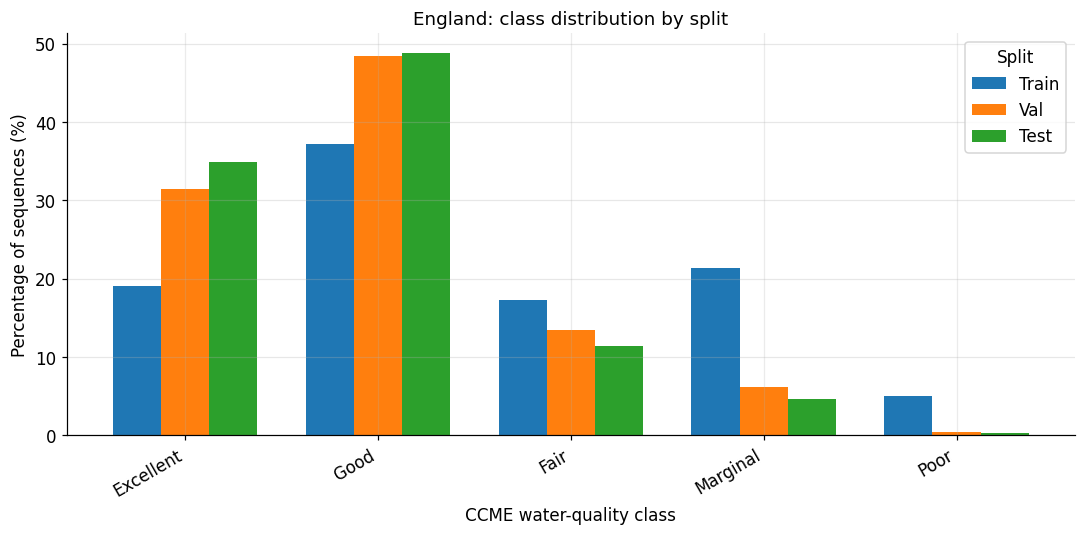

✓ saved figure: ireland_split_class_distribution_sequences.png/pdf


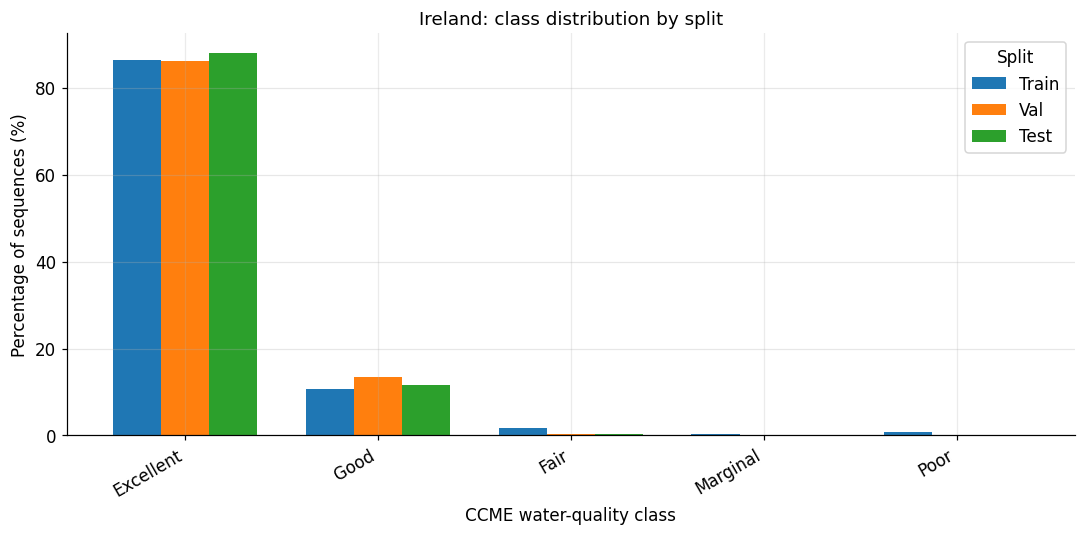

✓ saved figure: usa_split_class_distribution_sequences.png/pdf


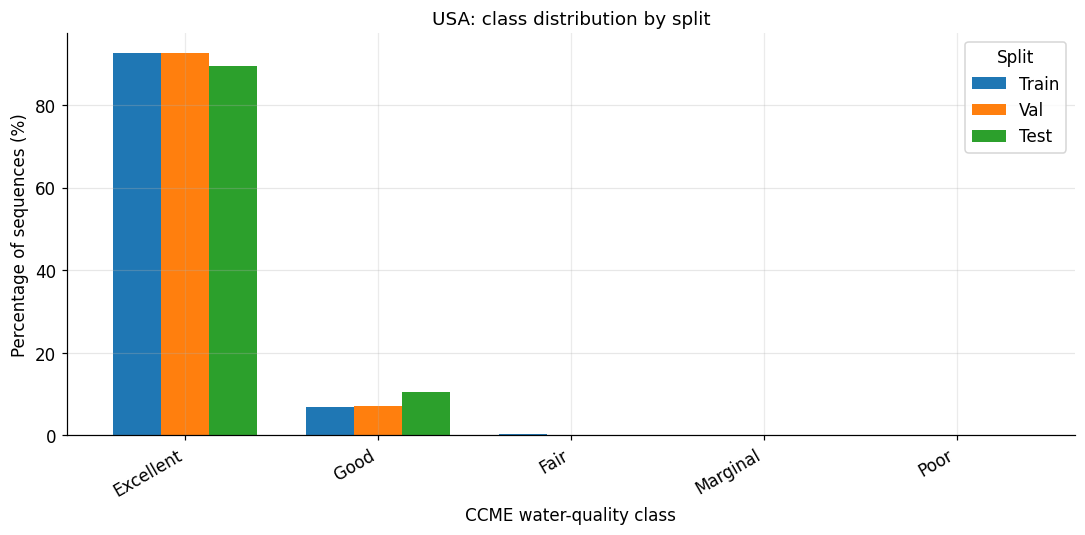


----------------------------------------------------------------------
The final preprocessing checks are valid.
The notebook now has split-level class distributions for Chapter 4.


In [32]:
# This cell prepares the class-balance tables and figures used to explain the final sequences.

class_names = [INT_TO_CLASS[i] for i in range(5)]

class_rows = []
modal_density_rows = []
split_class_rows = []

for client in ACTIVE_CLIENTS:
    for split in ["train", "val", "test"]:
        s = sequences[client][split]

        if s is None or s["X"].shape[0] == 0:
            row = {"Client": client, "Split": split, "N": 0}
            for cls_name in class_names:
                row[f"{cls_name}_N"] = 0
                row[f"{cls_name}_%"] = 0.0
            split_class_rows.append(row)
            continue

        y = s["y"]
        mask = s["mask"]
        counts = np.bincount(y, minlength=5)
        total = counts.sum()

        wide_row = {
            "Client": client,
            "Split": split,
            "N": int(total),
        }

        for cls_idx, cls_name in enumerate(class_names):
            count = int(counts[cls_idx])
            pct = round(100 * count / total, 2) if total > 0 else 0.0

            class_rows.append({
                "Client": client,
                "Split": split,
                "Class_id": cls_idx,
                "Class": cls_name,
                "Count": count,
                "%": pct,
            })

            wide_row[f"{cls_name}_N"] = count
            wide_row[f"{cls_name}_%"] = pct

        split_class_rows.append(wide_row)

        modal_density_rows.append({
            "Client": client,
            "Split": split,
            "N_sequences": int(mask.shape[0]),
            "Total_cells": int(mask.size),
            "Modal_cells": int(mask.sum()),
            "Modal_proxy_%": round(100 * mask.mean(), 2),
        })

class_distribution_df = pd.DataFrame(class_rows)
split_class_distribution_df = pd.DataFrame(split_class_rows)
modal_density_summary_df = pd.DataFrame(modal_density_rows)

save_table(class_distribution_df, "08B_class_distribution_per_split")
save_table(split_class_distribution_df, "08B_split_level_class_distribution_sequences")
save_table(modal_density_summary_df, "08B_modal_proxy_density_per_split")

manifest["class_distribution"] = {
    client: {
        split: {
            class_names[i]: int(np.bincount(sequences[client][split]["y"], minlength=5)[i])
            for i in range(5)
        }
        for split in ["train", "val", "test"]
        if sequences[client][split] is not None
    }
    for client in ACTIVE_CLIENTS
}

manifest["split_level_class_distribution"] = split_class_distribution_df.to_dict(orient="records")

manifest["modal_proxy_density"] = {
    row["Client"] + "_" + row["Split"]: {
        "N_sequences": int(row["N_sequences"]),
        "modal_proxy_percent": float(row["Modal_proxy_%"]),
    }
    for _, row in modal_density_summary_df.iterrows()
}

print("Class distribution per client and split, in long format:")
display(class_distribution_df)

print("\nClass distribution per client and split, in thesis-table format:")
display(split_class_distribution_df)

print("\nOverall modal-value proxy density per client and split:")
display(modal_density_summary_df)


# The next figures make the train/validation/test class balance visible for each active client.
for client in ACTIVE_CLIENTS:
    client_df = split_class_distribution_df[split_class_distribution_df["Client"] == client].copy()
    x = np.arange(len(class_names))
    width = 0.25

    fig, ax = plt.subplots(figsize=(10, 5))

    for offset, split in zip([-width, 0, width], ["train", "val", "test"]):
        row = client_df[client_df["Split"] == split].iloc[0]
        values = [row[f"{cls_name}_%"] for cls_name in class_names]
        ax.bar(x + offset, values, width, label=split.capitalize())

    ax.set_title(f"{client}: class distribution by split")
    ax.set_ylabel("Percentage of sequences (%)")
    ax.set_xlabel("CCME water-quality class")
    ax.set_xticks(x)
    ax.set_xticklabels(class_names, rotation=30, ha="right")
    ax.legend(title="Split")
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    save_figure(f"{client.lower()}_split_class_distribution_sequences", fig=fig)
    plt.show()

print("\n" + "-" * 70)
if all_tensor_checks_pass:
    print("The final preprocessing checks are valid.")
    print("The notebook now has split-level class distributions for Chapter 4.")
else:
    print("The final preprocessing checks did not all pass.")
    print("Inspect 08A_tensor_integrity_audit.csv before saving the outputs.")


# Section 9 — Save model-ready preprocessing outputs

This final section saves the validated preprocessing outputs to disk.

No new preprocessing is performed here. The section only writes the final
model-ready arrays and metadata so that the modelling notebooks can load them
without re-running the full preprocessing pipeline.

For each client, we save:

- `X_train`, `y_train`, `mask_train`, `site_ids_train`, `target_dates_train`
- `X_val`, `y_val`, `mask_val`, `site_ids_val`, `target_dates_val`
- `X_test`, `y_test`, `mask_test`, `site_ids_test`, `target_dates_test`

The fitted feature transformers were already saved in Section 6. The manifest
is updated and saved here to document the preprocessing configuration, sequence
counts, class distributions, modal-value proxy information, scaler statistics,
and output file paths.

In [33]:
# This cell saves the tensors and the sequence dates needed by the modeling notebooks.

saved_tensor_rows = []

for client in ACTIVE_CLIENTS:
    client_key = client.lower()
    out_path = os.path.join(TENSOR_DIR, f"{client_key}_stage1_sequences.npz")

    save_payload = {}

    for split in ["train", "val", "test"]:
        s = sequences[client][split]

        save_payload[f"X_{split}"] = s["X"].astype(np.float32)
        save_payload[f"y_{split}"] = s["y"].astype(np.int64)
        save_payload[f"mask_{split}"] = s["mask"].astype(bool)

        meta = s["meta"].copy()
        meta["input_start_date"] = pd.to_datetime(meta["input_start_date"])
        meta["input_end_date"] = pd.to_datetime(meta["input_end_date"])
        meta["target_date"] = pd.to_datetime(meta["target_date"])

        save_payload[f"site_ids_{split}"] = np.asarray(meta["site_id"].astype(str).to_numpy(), dtype="U")
        save_payload[f"input_start_dates_{split}"] = (
            np.asarray(meta["input_start_date"].dt.strftime("%Y-%m-%d").to_numpy(), dtype="U10")
        )
        save_payload[f"input_end_dates_{split}"] = (
            np.asarray(meta["input_end_date"].dt.strftime("%Y-%m-%d").to_numpy(), dtype="U10")
        )
        save_payload[f"target_dates_{split}"] = (
            np.asarray(meta["target_date"].dt.strftime("%Y-%m-%d").to_numpy(), dtype="U10")
        )

        saved_tensor_rows.append({
            "Client": client,
            "Split": split,
            "N": int(s["X"].shape[0]),
            "X_shape": str(tuple(s["X"].shape)),
            "y_shape": str(tuple(s["y"].shape)),
            "mask_shape": str(tuple(s["mask"].shape)),
            "Saved_dates": "input_start, input_end, target",
            "File": out_path,
        })

    np.savez_compressed(out_path, **save_payload)

saved_tensor_df = pd.DataFrame(saved_tensor_rows)
save_table(saved_tensor_df, "09A_saved_tensor_files")

print("Saved per-client compressed tensor files:")
display(saved_tensor_df)


✓ saved table : 09A_saved_tensor_files.csv  (9×8)
Saved per-client compressed tensor files:


,Client,Split,N,X_shape,y_shape,mask_shape,Saved_dates,File
0,England,train,76530,"(76530, 12, 8)","(76530,)","(76530, 12, 8)","input_start, input_end, target",/kaggle/working/preprocess_outputs/tensors/eng...
1,England,val,8490,"(8490, 12, 8)","(8490,)","(8490, 12, 8)","input_start, input_end, target",/kaggle/working/preprocess_outputs/tensors/eng...
2,England,test,11942,"(11942, 12, 8)","(11942,)","(11942, 12, 8)","input_start, input_end, target",/kaggle/working/preprocess_outputs/tensors/eng...
3,Ireland,train,27778,"(27778, 12, 8)","(27778,)","(27778, 12, 8)","input_start, input_end, target",/kaggle/working/preprocess_outputs/tensors/ire...
4,Ireland,val,4296,"(4296, 12, 8)","(4296,)","(4296, 12, 8)","input_start, input_end, target",/kaggle/working/preprocess_outputs/tensors/ire...
5,Ireland,test,5887,"(5887, 12, 8)","(5887,)","(5887, 12, 8)","input_start, input_end, target",/kaggle/working/preprocess_outputs/tensors/ire...
6,USA,train,30222,"(30222, 12, 8)","(30222,)","(30222, 12, 8)","input_start, input_end, target",/kaggle/working/preprocess_outputs/tensors/usa...
7,USA,val,1770,"(1770, 12, 8)","(1770,)","(1770, 12, 8)","input_start, input_end, target",/kaggle/working/preprocess_outputs/tensors/usa...
8,USA,test,1979,"(1979, 12, 8)","(1979,)","(1979, 12, 8)","input_start, input_end, target",/kaggle/working/preprocess_outputs/tensors/usa...


In [34]:
# This cell writes the manifest and a simple index of everything produced by preprocessing.

manifest["tensor_files"] = {
    client: os.path.join(TENSOR_DIR, f"{client.lower()}_stage1_sequences.npz")
    for client in ACTIVE_CLIENTS
}

manifest["scaler_files"] = {
    client: os.path.join(SCALER_DIR, f"{client.lower()}_feature_transformer.joblib")
    if os.path.exists(os.path.join(SCALER_DIR, f"{client.lower()}_feature_transformer.joblib"))
    else os.path.join(SCALER_DIR, f"{client.lower()}_scaler.joblib")
    for client in ACTIVE_CLIENTS
}

manifest["scaler_parameter_files"] = {
    client: os.path.join(SCALER_DIR, f"{client.lower()}_feature_transformer_params.json")
    for client in ACTIVE_CLIENTS
}

manifest["audit_files"] = sorted([
    os.path.join(AUDIT_DIR, f)
    for f in os.listdir(AUDIT_DIR)
    if f.endswith(".csv")
])

manifest["figure_files"] = sorted([
    os.path.join(FIG_DIR, f)
    for f in os.listdir(FIG_DIR)
    if f.endswith((".png", ".pdf"))
])

manifest["final_status"] = {
    "problem_formulation_check": "passed",
    "sequence_count_checkpoint": "passed",
    "scaling_checkpoint": "passed",
    "sequence_tensor_checkpoint": "passed",
    "future_target_audit": "passed",
    "final_sanity_checkpoint": "passed",
}

manifest_path = os.path.join(OUTPUT_DIR, "preprocess_manifest.json")

with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, default=str)

output_index_rows = []

for client in ACTIVE_CLIENTS:
    output_index_rows.append({
        "Artifact_type": "tensor_file",
        "Client": client,
        "Path": manifest["tensor_files"][client],
    })
    output_index_rows.append({
        "Artifact_type": "scaler_file",
        "Client": client,
        "Path": manifest["scaler_files"][client],
    })
    output_index_rows.append({
        "Artifact_type": "scaler_parameter_file",
        "Client": client,
        "Path": manifest["scaler_parameter_files"][client],
    })

output_index_rows.append({
    "Artifact_type": "manifest",
    "Client": "all",
    "Path": manifest_path,
})

for audit_file in manifest["audit_files"]:
    output_index_rows.append({
        "Artifact_type": "audit_csv",
        "Client": "all",
        "Path": audit_file,
    })

for figure_file in manifest["figure_files"]:
    output_index_rows.append({
        "Artifact_type": "figure",
        "Client": "all",
        "Path": figure_file,
    })

output_index_df = pd.DataFrame(output_index_rows)
save_table(output_index_df, "09B_output_index")

print(f"Manifest saved to: {manifest_path}")
print("\nFinal output index:")
display(output_index_df)

print("\n" + "-" * 70)
print("Preprocessing notebook complete. Model-ready Stage 1 tensors are saved.")
print("The next notebooks can use these tensors for local, centralized, and federated experiments.")


✓ saved table : 09B_output_index.csv  (33×3)
Manifest saved to: /kaggle/working/preprocess_outputs/preprocess_manifest.json

Final output index:


,Artifact_type,Client,Path
0,tensor_file,England,/kaggle/working/preprocess_outputs/tensors/eng...
1,scaler_file,England,/kaggle/working/preprocess_outputs/scalers/eng...
2,scaler_parameter_file,England,/kaggle/working/preprocess_outputs/scalers/eng...
3,tensor_file,Ireland,/kaggle/working/preprocess_outputs/tensors/ire...
4,scaler_file,Ireland,/kaggle/working/preprocess_outputs/scalers/ire...
5,scaler_parameter_file,Ireland,/kaggle/working/preprocess_outputs/scalers/ire...
6,tensor_file,USA,/kaggle/working/preprocess_outputs/tensors/usa...
7,scaler_file,USA,/kaggle/working/preprocess_outputs/scalers/usa...
8,scaler_parameter_file,USA,/kaggle/working/preprocess_outputs/scalers/usa...
9,manifest,all,/kaggle/working/preprocess_outputs/preprocess_...



----------------------------------------------------------------------
Preprocessing notebook complete. Model-ready Stage 1 tensors are saved.
The next notebooks can use these tensors for local, centralized, and federated experiments.


In [36]:

# Final packaging — include verified persistence predictions
# Run this in the COPY of Notebook 02, not the original.

from pathlib import Path
import shutil
import zipfile
import numpy as np
from IPython.display import FileLink, display

output_dir = Path("/kaggle/working/preprocess_outputs")
export_dir = Path("/kaggle/working/persistence_export")
zip_path = Path("/kaggle/working/preprocess_outputs.zip")

assert output_dir.is_dir(), f"Preprocessing folder missing: {output_dir}"
assert export_dir.is_dir(), (
    f"Persistence export folder missing: {export_dir}. "
    "Run the verified persistence export cell first."
)

expected = [
    f"persistence_{country}_test_preds.npz"
    for country in ("england", "ireland", "usa")
]

required_keys = {
    "y_true", "y_pred", "site_ids", "target_dates",
    "input_start_dates", "input_end_dates", "reference_sha256"
}

# 1. Verify that all three persistence files exist and are complete.
for filename in expected:
    src = export_dir / filename

    assert src.is_file() and src.stat().st_size > 0, (
        f"Missing persistence predictions: {src}"
    )

    with np.load(src, allow_pickle=False) as data:
        missing_keys = required_keys - set(data.files)
        assert not missing_keys, (
            f"{filename}: missing arrays {sorted(missing_keys)}"
        )

        assert (
            len(data["y_true"])
            == len(data["y_pred"])
            == len(data["site_ids"])
            == len(data["target_dates"])
        ), f"{filename}: inconsistent prediction lengths"

# 2. Copy persistence files into preprocessing output folder.
destination = output_dir / "persistence_export"
destination.mkdir(parents=True, exist_ok=True)

for filename in expected:
    shutil.copy2(export_dir / filename, destination / filename)

# 3. Rebuild the ZIP with all preprocessing outputs.
archive = shutil.make_archive(
    str(zip_path.with_suffix("")),
    "zip",
    root_dir=str(output_dir)
)

# 4. Confirm that all persistence files are included.
with zipfile.ZipFile(archive) as z:
    names = set(z.namelist())
    missing = [
        f"persistence_export/{filename}"
        for filename in expected
        if f"persistence_export/{filename}" not in names
    ]

    assert not missing, f"ZIP packaging failed: {missing}"

print(f"Saved ZIP: {archive}")
print("Verified persistence predictions included:")

for filename in expected:
    print("  persistence_export/" + filename)

display(FileLink(archive))


Saved ZIP: /kaggle/working/preprocess_outputs.zip
Verified persistence predictions included:
  persistence_export/persistence_england_test_preds.npz
  persistence_export/persistence_ireland_test_preds.npz
  persistence_export/persistence_usa_test_preds.npz


/kaggle/working/preprocess_outputs.zip